# ITT Corredor San Fernando (Yawa), Cali

**Zona:** Corredor San Fernando (Yawa) — proyecto de intervención urbana en el sector de San Fernando.
**Comuna:** 19
**Área del polígono:** 265.33 ha (2,653,275.2 m² ≈ 2.653 km²) — medida sobre el polígono real en EPSG:3115. El valor exacto se recalcula en runtime en la Celda 4 (`AREA_ZONA_HA` / `AREA_ZONA_M2`).
**Período:** 2023 — 2026 (2026 parcial, cobertura real varía por fuente, ver Celda 6)
**Notebook base:** replica la estructura y metodología de `04_itt_barrio_obrero_5dim.ipynb` y las mejoras de `08_itt_ciudad_paraiso_5dim.ipynb` (referencias vigentes del repo), con 2 mejoras puntuales documentadas explícitamente donde aparecen:

1. **Verificación espacial real** (Celda 4B) antes de agregar cualquier indicador — no se confía en los campos `nom_barrio`/`comuna` de las fuentes, se valida con `geopandas.sjoin` contra el polígono real.
2. **Desarrollo Económico con umbrales `ref_min/ref_max` fijos** (Celda DE), en vez de min-max relativo de la propia muestra (defecto conocido y documentado en `docs/06_arquitectura_aws_itt_obrero.md` §9.2, presente en Obrero/Roosevelt/Av. Ciudad de Cali).

> **ESTADO (datos pendientes):** por ahora SOLO está cargado el polígono de la zona (`geojson_Corredor_San_fernando.geojson`, polígono único de 265.33 ha). Las fuentes por dimensión (seguridad, movilidad, cohesión, entorno urbano, desarrollo económico) **aún no se han agregado** — la Celda 3 las marcará como `FALTA` hasta que se carguen en `data/itt_Corredor_San_fernando_Yawa/` siguiendo la estructura por dimensión del resto de zonas. Los umbrales `ref_min/ref_max` (Celda 3) son placeholders heredados de Ciudad Paraíso y **deben recalibrarse** con los datos reales de esta zona cuando lleguen.

## Alcance declarado

- **Educación y Desarrollo** NO se calcula en este repo — se gestiona en otro repositorio. La dimensión `DesSocial` en este notebook se calcula **solo** con los componentes de conflictividad (VIF, Riñas, SPA) — el mecanismo de `nanmean` ya soporta esto de forma nativa sin tocar la fórmula del ITT (ver Celda 7).
- **Entorno Urbano:** se calcula con datos propios (NDVI anual + censo arbóreo) una vez se agreguen a `data/itt_Corredor_San_fernando_Yawa/5_Dimension_Entorno_Urbano/`, con el método `score_entorno_u = mean(score_ndvi, score_arbolado)` (idéntico a Ciudad Paraíso / Av. Ciudad de Cali). El NDVI aporta la señal temporal; el censo arbóreo es un corte único.

## Celda 1 — Instalación de dependencias (Colab)

In [31]:
import subprocess, sys

def check_pkg(import_name, pip_name=None):
    """Importa import_name; si falta, instala pip_name (por defecto = import_name).
    Necesario para casos como PIL->pillow donde el nombre de import != nombre pip."""
    try:
        __import__(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name or import_name, "-q"])

# rasterio: lee los rasters NDVI de Entorno Urbano (Celda 3B).
# osmnx: red peatonal OSM del mapa (Celda 5). PIL(pillow): overlays NDVI del mapa.
# Colab NO trae rasterio/osmnx preinstalados, por eso van en esta lista.
for p in ["geopandas", "pyproj", "shapely", "openpyxl", "seaborn", "folium", "rasterio", "osmnx"]:
    check_pkg(p)
check_pkg("PIL", "pillow")
print("Dependencias verificadas")


Dependencias verificadas


## Celda 1B — Clonar/actualizar el repo (Colab)

**Importante:** esta celda SÍ se ejecuta (no está comentada). Si ya existe `/content/itt_repos_cali`
hace `git pull` en vez de clonar de nuevo — así se puede re-ejecutar el notebook sin reiniciar el runtime
cada vez que se actualiza el repo. Mismo patrón que `04_itt_barrio_obrero_5dim.ipynb` (Celda 3A).

In [32]:
import os
from pathlib import Path

REPO_URL  = "https://github.com/j0rg3c45/Itt_repos_cali.git"
REPO_PATH = "/content/itt_repos_cali"

# El repo completo pesa ~250 MB (datos de 6 zonas + historia git). Este notebook
# SOLO usa data/itt_Corredor_San_fernando_Yawa (~11 MB). Para que el clon en Colab sea rapido se
# usa clone superficial (--depth 1, sin historia) + sparse-checkout (solo las
# carpetas que el notebook toca). Baja la descarga de ~250 MB a ~12 MB.
#
# Es robusto ante force-push: siempre borra la copia previa y clona limpio, asi
# nunca se queda con archivos viejos (causa del DataSourceError anterior).
# NO se incluye 'notebooks/' (pesa ~67 MB por los mapas folium embebidos y el
# notebook ya esta cargado en memoria en Colab, no hace falta descargarlo).
SPARSE_DIRS = [
    "data/itt_Corredor_San_fernando_Yawa",   # unica carpeta de datos que usa el notebook (~11 MB)
    "docs", "tools", "agent", "outputs",   # livianas (<1 MB en total)
]

# Se usa subprocess en vez de magics '!...{expr}' porque Colab/IPython no interpola
# bien expresiones como {' '.join(...)} dentro de una linea magic (da SyntaxError).
import shutil, subprocess
shutil.rmtree(REPO_PATH, ignore_errors=True)
subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
                REPO_URL, REPO_PATH], check=True)
subprocess.run(["git", "-C", REPO_PATH, "sparse-checkout", "set", *SPARSE_DIRS], check=True)

DATA_DIR_CHECK = Path("/content/itt_repos_cali/data/itt_Corredor_San_fernando_Yawa")
print()
print("Carpetas disponibles en data/itt_Corredor_San_fernando_Yawa:")
if DATA_DIR_CHECK.exists():
    for p in sorted(DATA_DIR_CHECK.iterdir()):
        print(f"  {'OK' if p.is_dir() or p.suffix == '.geojson' else '  '}  {p.name}")
else:
    print("  NO EXISTE — revisar que el clone/pull de arriba haya terminado sin error.")

# Verificacion explicita de la dimension 5 (la que originaba el DataSourceError).
_eu = DATA_DIR_CHECK / "5_Dimension_Entorno_Urbano" / "CENSO_ARBOREO_san_fernando.geojson"
print()
if _eu.exists():
    print("OK  Dimension 5 presente (censo arboreo + NDVI). Puedes continuar.")
else:
    print("FALTA  5_Dimension_Entorno_Urbano no esta en la copia local del repo.")
    print("       Fuerza una copia limpia ejecutando en una celda nueva:")
    print("         !rm -rf /content/itt_repos_cali")
    print("         !git clone https://github.com/j0rg3c45/Itt_repos_cali.git /content/itt_repos_cali")



Carpetas disponibles en data/itt_Corredor_San_fernando_Yawa:
  OK  1_Dimension_Seguridad
  OK  2_Dimension_Cohesion_Social
  OK  3_Dimension_Movilidad
  OK  5_Dimension_Entorno_Urbano
  OK  6_Dimension_Educacion
  OK  geojson_Corredor_San_fernando.geojson
      geojson_Corredor_San_fernando.qmd

FALTA  5_Dimension_Entorno_Urbano no esta en la copia local del repo.
       Fuerza una copia limpia ejecutando en una celda nueva:
         !rm -rf /content/itt_repos_cali
         !git clone https://github.com/j0rg3c45/Itt_repos_cali.git /content/itt_repos_cali


## Celda 2 — Importaciones y configuración visual

In [33]:
import json, os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import folium
from shapely.geometry import Point
warnings.filterwarnings("ignore")

# Paleta Okabe-Ito (accesible para daltonismo) — misma paleta que el resto del proyecto
OKI_AZUL     = "#0072B2"
OKI_NARANJA  = "#E69F00"
OKI_VERDE    = "#009E73"
OKI_AMARILLO = "#F0E442"
OKI_AZUL_C   = "#56B4E9"
OKI_BERMELL  = "#D55E00"
OKI_MORADO   = "#CC79A7"
OKI_GRIS     = "#333333"
BG = "#F4F6F9"

NIVEL_COLORS = {
    "Activacion":     OKI_BERMELL,
    "Consolidacion":  OKI_NARANJA,
    "Transformacion": OKI_VERDE,
    "Escala":         OKI_AZUL,
}

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})
print("Configuracion visual lista - Paleta Okabe-Ito activa")


Configuracion visual lista - Paleta Okabe-Ito activa


## Celda 3 — Parámetros, rutas, pesos y umbrales ref_min/ref_max

In [34]:
REPO = Path("/content/itt_repos_cali")
D    = REPO / "data" / "itt_Corredor_San_fernando_Yawa"

# Para ejecucion local descomentar:
# REPO = Path(".")
# D    = REPO / "data" / "itt_Corredor_San_fernando_Yawa"

# Rutas a los archivos REALES de San Fernando. Cada fuente DATIC viene en DOS partes:
#   - histórico 2023 -> 2026-Q1  (sufijo _2023_2026T1)
#   - extensión 2026 Q2-Q3        (sufijo _04012026_09302026 / _26092026)
# La Celda 4 une ambas por fuente. Siniestros viene en un solo archivo.
DIM1 = D / "1_Dimension_Seguridad"
DIM2 = D / "2_Dimension_Cohesion_Social"   # OJO: carpeta SIN tilde en 'Dimension'
DIM3 = D / "3_Dimension_Movilidad"
PATHS = {
    "poligono":     str(D / "geojson_Corredor_San_fernando.geojson"),
    "poligono_shp": str(D / "geojson_Corredor_San_fernando.geojson"),
    # Seguridad: histórico + extensión Q2-Q3 2026 (listas -> se concatenan en Celda 4)
    "homicidios":  [str(DIM1 / "DATIC_homicidios_2023_2026T1.geojson"),
                    str(DIM1 / "DATIC_homicidios_04012026_26092026.geojson")],
    "hurtos":      [str(DIM1 / "DATIC_hurtos_2023_2026T1.geojson"),
                    str(DIM1 / "DATIC_hurtos_04012026_09302026.geojson")],
    "comparendos": [str(DIM1 / "DATIC_comparendos_2023_2026T1.geojson"),
                    str(DIM1 / "DATIC_comparendos_04012026_09302026.geojson")],
    # Cohesión Social: VIF histórico + extensión Q2-Q3 2026
    "vif":         [str(DIM2 / "DATIC_violencia_intrafamiliar_2023_2026T1.geojson"),
                    str(DIM2 / "DATIC_violencia_intrafamiliar_04012026_09302026.geojson")],
    # Movilidad: siniestros (archivo único, cobertura hasta 2026-Q2)
    "siniestros":  str(DIM3 / "BD_SINIESTROS_2023_2026_COMUNA_BARRIO.geojson"),
    # Fuentes aún no disponibles para esta zona (quedan como FALTA hasta que se carguen):
    "vbg":                str(DIM2 / "VBG_2025.geojson"),
    "registro_mercantil": str(D / "4_Dimension_Desarrollo_Economico" / "registro_mercantil_2025.geojson"),
    # Desarrollo Económico: fuente ÚNICA consolidada (Cámara de Comercio filtrada al polígono).
    "de_consolidado":     str(D / "4_Dimension_Desarrollo_Economico" / "registro_mercantil_SF_2023_2026_consolidado.json"),
    # Vivienda (déficit habitacional 2024, corte único estructural) -> componente de Entorno Urbano
    "deficit_habitacional_shp": str(D / "5_Dimension_Entorno_Urbano" / "sec_vivienda" / "DEF_HAB_SISBEN.shp"),
    "subsidios_vivienda":       str(D / "5_Dimension_Entorno_Urbano" / "sec_vivienda" / "1_BASE DE DATOS DE SUBSIDIOS ASIGNADOS DESDE EL 2024 A LA FECHA_021026.xlsx"),
    "censo_arboreo":      str(D / "5_Dimension_Entorno_Urbano" / "CENSO_ARBOREO_san_fernando.geojson"),
}
# ── Subzonas internas del corredor + punto focal Yawa (shapefiles -> GeoJSON EPSG:4326) ──
# Se dibujan en el mapa (Celda 5) y se usan para el análisis comparativo por subzona (celda final).
SUBZONAS = {
    "Subzona 1": str(D / "Corredor_San_fernando_zona_01.geojson"),  # 71.3 ha
    "Subzona 2": str(D / "Corredor_San_fernando_zona_02.geojson"),  # 88.8 ha
    "Subzona 3": str(D / "Corredor_San_fernando_zona_03.geojson"),  # 50.2 ha
}
PATH_YAWA = str(D / "yawa.geojson")   # punto focal Yawa (2.5 ha)
# Educación: consolidado liviano (IE Liceo Departamental, único colegio dentro del polígono).
# Generado una sola vez por scripts_educ/build_educacion_san_fernando.py (SIMAT/SIMPADE -> JSON).
PATH_EDUC = str(D / "6_Dimension_Educacion" / "educacion_SF_2023_2026_consolidado.json")

# Serie NDVI anual propia de la zona (un raster por año)
PATHS_NDVI = {
    ano: str(D / "5_Dimension_Entorno_Urbano" / "san_fernando_ndvi" / f"san_fernando_ndvi_{ano}.tif")
    for ano in [2023, 2024, 2025, 2026]
}

ANIOS = [2023, 2024, 2025, 2026]
ANO_CORTE = 2026
ANIOS_PARCIALES = [2026]   # cobertura incompleta en TODAS las fuentes (DATIC hasta Q1, siniestros
                            # hasta Q2) — no es un año comparable contra 2023-2025 en la clasificacion
                            # final (ver clasificar() en Celda 7): un año parcial con conteos acumulados
                            # bajos SOLO por estar incompleto, medido con umbrales anuales completos,
                            # produce una mejora artificial (el mismo defecto ya documentado para
                            # notebooks/06_itt_avenida_ciudad_de_cali_5dim.ipynb en
                            # docs/06_arquitectura_aws_itt_obrero.md §9.3). El ITT numerico de 2026 se
                            # calcula y se muestra igual (es informativo), pero no se le asigna un nivel
                            # real de transformacion.
ZONA_NOMBRE = "Corredor San Fernando (Yawa)"
COMUNA_PROXY = "19"   # San Pascual, El Calvario, San Juan Bosco, Santa Rosa

# ── Pesos ITT: 5 dimensiones (suma = 1.00) — IDENTICOS a Barrio Obrero,            ──
# ── por indicación explícita de mantenerse lo más cerca posible de la metodología ──
PESOS = {
    "Seguridad": 0.27,
    "Movilidad": 0.22,
    "DesSocial": 0.19,   # en esta zona = SOLO Cohesión (VIF+Riñas+SPA); Educación fuera de alcance (ver nota)
    "EntornoU":  0.17,
    "DesEco":    0.15,
}

# ── Umbrales de normalización ref_min/ref_max ────────────────────────────────
# Calibrados sobre el rango real observado 2023-2025 en Corredor San Fernando (Yawa) (ver Celda 6),
# NO reutilizados de Barrio Obrero: homicidios y riñas en esta zona superan por mucho
# los umbrales de Obrero (16 homicidios/año vs. ref_max=5 de Obrero; 418 riñas/año vs.
# ref_max=10 de Obrero) — usar los de Obrero aquí saturaría todo en score=0 y escondería
# la mejora real año a año. Regla aplicada: ref_min por debajo del mínimo observado
# (aspiracional), ref_max con margen razonable sobre el máximo observado (sección 6.3
# de agent/knowledge_base/Guia_ITT_Metodologia_Notebook.md). Pendiente de validación por
# un experto local del territorio (regla también de la misma sección 6.3).
# Umbrales con Barrio Obrero como GUIA de estructura/lógica, escalados al rango real
# observado 2023-2025 de San Fernando (zona grande, 265 ha; conteos mucho mayores que
# Obrero). Regla: ref_min bajo el mínimo observado, ref_max con margen sobre el máximo
# (sección 6.3 de Guia_ITT_Metodologia_Notebook.md). Pendiente de validación por experto local.
REFS = {
    # Seguridad — obs. 2023-2025: homicidios 8-9 | hurtos 1245-1629
    "homicidios":      (0,    15,   True,  "Homicidios anuales en la zona"),
    "hurtos":          (800,  2000, True,  "Hurtos anuales en la zona"),
    # Movilidad — obs.: siniestralidad 142-195 | lesionados 123-168 | mortales 3-5
    "siniestralidad":  (80,   240,  True,  "Siniestros viales anuales"),
    "lesionados":      (70,   210,  True,  "Accidentes con lesionados anuales"),
    "mortales":        (0,    8,    True,  "Accidentes mortales anuales"),
    # Cohesión Social (= DesSocial en esta zona) — obs.: vif 52-68 | rinas 563-925 | spa 356-696
    "vif":             (30,   90,   True,  "Violencia intrafamiliar anual"),
    "rinas":           (400,  1100, True,  "Riñas / conflictividad anual"),
    "spa":             (200,  850,  True,  "Sustancias psicoactivas (comparendos) anuales"),
    # Entorno Urbano (inverso=False: mas verde / mas arboles = mejor). Umbrales
    # calibrados sobre la serie real de la zona (ver Celda 3B, se recalculan ahi
    # con el rango observado y se sobrescriben estos placeholders).
    "ndvi":            (0.05, 0.20, False, "NDVI medio anual (vegetacion) del raster de la zona"),
    "arbolado":        (0,    400, False, "Arboles vivos censados dentro del poligono"),
}

# ── Entorno Urbano: datos propios (NDVI + censo arbóreo). Los scores se calculan
#    por año en la Celda 3B (df_entorno). FUENTE_ENTORNO_U se fija allí. ──
FUENTE_ENTORNO_U = "NDVI anual + censo arbóreo (datos propios de la zona)"

print(f"Zona: {ZONA_NOMBRE}  |  Periodo: {ANIOS[0]}-{ANIOS[-1]}  |  Comuna proxy: {COMUNA_PROXY}")
for nombre, path in PATHS.items():
    _rutas = path if isinstance(path, (list, tuple)) else [path]
    _exist = [os.path.exists(r) for r in _rutas]
    mark = "OK   " if all(_exist) else ("PARCIAL" if any(_exist) else "FALTA")
    _nombres = ", ".join(os.path.basename(r) for r in _rutas)
    print(f"  {mark:7s}  {nombre}: {_nombres}")
print()
print("Pesos ITT (5 dimensiones):", " | ".join(f"{k}={v:.0%}" for k, v in PESOS.items()))
print(f"Suma pesos: {sum(PESOS.values()):.2f}")
print()
print("Umbrales de normalizacion:")
for ind, (rmin, rmax, inv, desc) in REFS.items():
    print(f"  {ind:18s}  [{rmin:>4} - {rmax:>4}]  inv={inv}  — {desc}")


Zona: Corredor San Fernando (Yawa)  |  Periodo: 2023-2026  |  Comuna proxy: 19
  OK       poligono: geojson_Corredor_San_fernando.geojson
  OK       poligono_shp: geojson_Corredor_San_fernando.geojson
  OK       homicidios: DATIC_homicidios_2023_2026T1.geojson, DATIC_homicidios_04012026_26092026.geojson
  OK       hurtos: DATIC_hurtos_2023_2026T1.geojson, DATIC_hurtos_04012026_09302026.geojson
  OK       comparendos: DATIC_comparendos_2023_2026T1.geojson, DATIC_comparendos_04012026_09302026.geojson
  OK       vif: DATIC_violencia_intrafamiliar_2023_2026T1.geojson, DATIC_violencia_intrafamiliar_04012026_09302026.geojson
  OK       siniestros: BD_SINIESTROS_2023_2026_COMUNA_BARRIO.geojson
  FALTA    vbg: VBG_2025.geojson
  FALTA    registro_mercantil: registro_mercantil_2025.geojson
  FALTA    censo_arboreo: CENSO_ARBOREO_san_fernando.geojson

Pesos ITT (5 dimensiones): Seguridad=27% | Movilidad=22% | DesSocial=19% | EntornoU=17% | DesEco=15%
Suma pesos: 1.00

Umbrales de normalizacion:


## Celda 3B — Entorno Urbano real: NDVI anual + censo arbóreo

**Actualizado 2026-10-07.** Antes esta celda calculaba un *proxy* de déficit habitacional de la Comuna 3
porque la zona no tenía datos ambientales propios. Ya los tiene (`5_Dimension_Entorno_Urbano/`), así que se
reemplaza por el cálculo real, con el **mismo método que `06_itt_avenida_ciudad_de_cali_5dim.ipynb`**:

- **NDVI**: media del ráster de cada año (`np.nanmean`), descartando `nodata`. Aporta la señal temporal
  (la vegetación sí cambia año a año).
- **Arbolado**: conteo de árboles vivos (`estado_arb ∈ {Vivo, Nuevo}`) dentro del polígono, verificado por
  `sjoin` igual que el resto de fuentes. Es un corte único del censo, así que es constante en los 4 años.
- `score_entorno_u = mean(score_ndvi, score_arbolado)` con `inverso=False` (más verde / más árboles = mejor).

Los umbrales `ndvi`/`arbolado` de la Celda 3 se **recalibran aquí** sobre el rango real observado de la zona
(regla sección 6.3 de `agent/knowledge_base/Guia_ITT_Metodologia_Notebook.md`): `ref_min` por debajo del mínimo
observado, `ref_max` con margen sobre el máximo. Pendiente de validación por experto local del territorio.

In [35]:
# Fallback por si la Celda 1 no se corrio: rasterio no viene preinstalado en Colab.
try:
    import rasterio
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "rasterio", "-q"])
    import rasterio

def _ndvi_medio(path):
    """Media NDVI del raster, descartando nodata y centinelas -9999."""
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float64")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        arr[arr <= -9999] = np.nan
        return float(np.nanmean(arr))

# ── NDVI medio por año (señal temporal de Entorno Urbano) ────────────────────
ndvi_por_anio = {}
for ano in ANIOS:
    p = PATHS_NDVI.get(ano)
    ndvi_por_anio[ano] = _ndvi_medio(p) if (p and os.path.exists(p)) else np.nan

# ── Censo arbóreo: árboles VIVOS dentro del polígono real (sjoin, no campo 'comuna') ─
# gdf_zona_wgs se carga normalmente en la Celda 4; aqui lo cargamos si aun no existe
# para que esta celda sea autosuficiente y funcione en cualquier orden de ejecucion.
if "gdf_zona_wgs" not in dir():
    gdf_zona_wgs = gpd.read_file(PATHS["poligono"]).to_crs("EPSG:4326")

# Censo arbóreo: tolerante a que la fuente aún no exista en la zona.
if os.path.exists(PATHS["censo_arboreo"]):
    gdf_arb_all = gpd.read_file(PATHS["censo_arboreo"]).to_crs("EPSG:4326")
    _join_arb = gpd.sjoin(gdf_arb_all, gdf_zona_wgs[["geometry"]], how="left", predicate="within")
    _dentro_arb = _join_arb["index_right"].notna()
    _vivos = gdf_arb_all["estado_arb"].astype(str).str.strip().isin(["Vivo", "Nuevo"])
    gdf_arb = gdf_arb_all[_dentro_arb.values & _vivos.values].copy()
    ARBOLADO_VIVO = int(len(gdf_arb))
    ARBOLADO_TOTAL_CENSADO = int(_dentro_arb.sum())
else:
    print("  [FALTA] censo arbóreo -> arbolado = 0 (Entorno Urbano usará solo NDVI si existe)")
    gdf_arb = gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")
    ARBOLADO_VIVO = 0
    ARBOLADO_TOTAL_CENSADO = 0

# ── Recalibrar umbrales REFS['ndvi'] y REFS['arbolado'] sobre el rango real de la zona ─
_ndvi_vals = [v for v in ndvi_por_anio.values() if pd.notna(v)]
if _ndvi_vals:
    _nmin, _nmax = min(_ndvi_vals), max(_ndvi_vals)
    _margen = max((_nmax - _nmin) * 0.5, 0.02)
    REFS["ndvi"] = (round(max(0.0, _nmin - _margen), 3), round(_nmax + _margen, 3), False,
                    "NDVI medio anual (vegetacion) del raster de la zona")
REFS["arbolado"] = (0, max(1, round(ARBOLADO_VIVO * 1.5)), False,
                    "Arboles vivos censados dentro del poligono")

# ── Tabla anual de Entorno Urbano (lo que consume la Celda 7) ────────────────
df_entorno = pd.DataFrame({
    "año":      ANIOS,
    "ndvi":     [ndvi_por_anio[a] for a in ANIOS],
    "arbolado": [ARBOLADO_VIVO] * len(ANIOS),   # corte único del censo (constante en el tiempo)
})

print(f"Entorno Urbano REAL activado para {ZONA_NOMBRE} (NDVI + censo arbóreo)")
print(f"Censo arbóreo: {ARBOLADO_TOTAL_CENSADO} árboles dentro del polígono | {ARBOLADO_VIVO} vivos/nuevos (usados)")
print(f"Umbral NDVI recalibrado: {REFS['ndvi'][0]} - {REFS['ndvi'][1]}  |  Umbral arbolado: 0 - {REFS['arbolado'][1]}")
print()
print("NDVI medio por año:")
for a in ANIOS:
    v = ndvi_por_anio[a]
    print(f"  {a}: {'N/D' if pd.isna(v) else f'{v:.4f}'}")


  [FALTA] censo arbóreo -> arbolado = 0 (Entorno Urbano usará solo NDVI si existe)
Entorno Urbano REAL activado para Corredor San Fernando (Yawa) (NDVI + censo arbóreo)
Censo arbóreo: 0 árboles dentro del polígono | 0 vivos/nuevos (usados)
Umbral NDVI recalibrado: 0.05 - 0.2  |  Umbral arbolado: 0 - 1

NDVI medio por año:
  2023: N/D
  2024: N/D
  2025: N/D
  2026: N/D


## Celda 4 — Carga de datos crudos (GeoJSON + polígono)

In [36]:
def load_gj(path):
    """Carga un GeoJSON y devuelve una FeatureCollection.
    - Acepta una ruta (str) o una LISTA de rutas: en ese caso CONCATENA los features
      de todas (p.ej. histórico 2023-2026T1 + extensión Q2-Q3 2026 en una sola serie).
    - Si un archivo no existe (fuente aún no agregada), lo omite sin romper — así el
      notebook corre por fases mientras se cargan las dimensiones."""
    rutas = path if isinstance(path, (list, tuple)) else [path]
    feats = []
    for r in rutas:
        if not os.path.exists(r):
            print(f"  [FALTA] {os.path.basename(r)} -> 0 registros de esta parte")
            continue
        with open(r, encoding="utf-8") as f:
            feats.extend(json.load(f).get("features", []))
    return {"type": "FeatureCollection", "features": feats}

# Poligono real de la zona — se usa para la verificacion espacial de la Celda 4B,
# no solo para el mapa.
gdf_zona = gpd.read_file(PATHS["poligono"])
gdf_zona_wgs = gdf_zona.to_crs("EPSG:4326")
AREA_ZONA_M2 = round(gdf_zona.to_crs("EPSG:3115").geometry.area.sum(), 1)
AREA_ZONA_HA = round(AREA_ZONA_M2 / 10000, 2)
AREA_ZONA_KM2 = round(AREA_ZONA_M2 / 1e6, 4)
print(f"Area real del poligono (EPSG:3115): {AREA_ZONA_HA} ha  |  {AREA_ZONA_M2:,.1f} m2  |  {AREA_ZONA_KM2} km2")

raw_hom  = load_gj(PATHS["homicidios"])
raw_hur  = load_gj(PATHS["hurtos"])
raw_comp = load_gj(PATHS["comparendos"])
raw_vif  = load_gj(PATHS["vif"])
raw_vbg  = load_gj(PATHS["vbg"])
raw_sin  = load_gj(PATHS["siniestros"])
raw_de   = load_gj(PATHS["registro_mercantil"])

for n, r in [("Homicidios",raw_hom),("Hurtos",raw_hur),("Comparendos",raw_comp),
             ("VIF",raw_vif),("VBG",raw_vbg),("Siniestros",raw_sin),
             ("Registro Mercantil",raw_de)]:
    print(f"  {n:20s}: {len(r['features']):>5} registros")


Area real del poligono (EPSG:3115): 265.33 ha  |  2,653,275.2 m2  |  2.6533 km2
  [FALTA] VBG_2025.geojson -> 0 registros de esta parte
  [FALTA] registro_mercantil_2025.geojson -> 0 registros de esta parte
  Homicidios          :    28 registros
  Hurtos              :  5013 registros
  Comparendos         :  8068 registros
  VIF                 :   214 registros
  VBG                 :     0 registros
  Siniestros          :   554 registros
  Registro Mercantil  :     0 registros


## Celda 4B — Verificación espacial real (mejora sobre la metodología de Obrero)

A diferencia de Barrio Obrero (donde `nom_barrio == "Barrio Obrero"` bastaba porque el único ruido eran
barrios vecinos inmediatos), en Corredor San Fernando (Yawa) los campos `nom_comuna`/`BARRIO` de las fuentes DATIC y
Cámara de Comercio son poco confiables (ej. comparendos trae `nom_comuna` como `"C-22 LA MARIA"` para
puntos que están físicamente en El Calvario; Registro Mercantil trae negocios etiquetados en 14 comunas
distintas). **Esta celda no confía en esos campos** — hace `point-in-polygon` real contra la geometría
del polígono con `geopandas.sjoin`, y usa ese resultado como único filtro de verdad. Si el % dentro no es
cercano a 100%, es señal de que el archivo fuente trae puntos de fuera de la zona y hay que filtrar antes
de agregar.

In [37]:
def verificar_espacial(raw, nombre):
    # Fuente aún no agregada: máscara vacía, sin romper.
    if not raw["features"]:
        print(f"  {nombre:20s}:     0/    0 dentro del poligono  (fuente ausente)")
        return pd.Series([], dtype=bool)
    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs="EPSG:4326")
    join = gpd.sjoin(gdf, gdf_zona_wgs[["geometry"]], how="left", predicate="within")
    dentro = join["index_right"].notna()
    pct = dentro.mean() * 100
    print(f"  {nombre:20s}: {dentro.sum():>5}/{len(gdf):>5} dentro del poligono  ({pct:5.1f}%)")
    return dentro

print(f"Verificacion espacial contra el poligono real ({AREA_ZONA_HA} ha):")
mask_hom  = verificar_espacial(raw_hom,  "Homicidios")
mask_hur  = verificar_espacial(raw_hur,  "Hurtos")
mask_comp = verificar_espacial(raw_comp, "Comparendos")
mask_vif  = verificar_espacial(raw_vif,  "VIF")
mask_sin  = verificar_espacial(raw_sin,  "Siniestros")
mask_de   = verificar_espacial(raw_de,   "Registro Mercantil")
print()
print("Nota: si alguna fuente no llega a ~100%, filtrar por la mascara correspondiente")
print("(mask_*) antes de la Celda 6, en vez de confiar en nom_barrio/comuna.")


Verificacion espacial contra el poligono real (265.33 ha):
  Homicidios          :    28/   28 dentro del poligono  (100.0%)


  Hurtos              :  5013/ 5013 dentro del poligono  (100.0%)
  Comparendos         :  8068/ 8068 dentro del poligono  (100.0%)
  VIF                 :   214/  214 dentro del poligono  (100.0%)
  Siniestros          :   554/  554 dentro del poligono  (100.0%)
  Registro Mercantil  :     0/    0 dentro del poligono  (fuente ausente)

Nota: si alguna fuente no llega a ~100%, filtrar por la mascara correspondiente
(mask_*) antes de la Celda 6, en vez de confiar en nom_barrio/comuna.


## Celda 5 — Mapa interactivo multicapa

Mapa navegable en **WGS84 (EPSG:4326)** que superpone todas las capas de la zona, cada una activable
desde el control de capas:

- **5 capas base** alternables: CartoDB Claro, OpenStreetMap, Esri Satélite, Google Streets, Google Satélite.
- **Polígono** de la zona y, si existe, el eje/tramo.
- **Red peatonal de OpenStreetMap** (líneas) + **nodos/intersecciones**, descargados con `osmnx`
  (`graph_from_polygon(..., network_type="walk")`).
- **Mapa de calor de intersecciones** reales (`street_count > 2`), apagado por defecto.
- **Capas de eventos** (comparendos→riñas/SPA, hurtos, homicidios, VIF, censo arbóreo), apagadas por defecto.
- **Overlays NDVI** 2023-2026 (uno por año, colormap verde, apagados por defecto) para ver la evolución
  de la vegetación sobre el territorio.

La descarga del grafo OSM necesita internet; si falla (sin red), el mapa se construye igual sin la red
peatonal y avisa por consola — no rompe la ejecución del resto del notebook.

In [38]:
# ── Dependencias del mapa (osmnx se instala si falta: no viene con el resto) ──
try:
    import osmnx as ox
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "osmnx", "-q"])
    import osmnx as ox
from folium.plugins import HeatMap

# ── PASO 1: mapa base centrado en el centroide del poligono (WGS84) ──────────
centroid = gdf_zona_wgs.geometry.centroid.iloc[0]
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=16, tiles=None)

# ── PASO 2: capas base alternables (overlay=False) ───────────────────────────
folium.TileLayer("CartoDB positron", name="CartoDB Claro").add_to(m)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Esri Satélite",
).add_to(m)
folium.TileLayer(
    tiles="http://{s}.google.com/vt/lyrs=m&x={x}&y={y}&z={z}",
    attr="Google", name="Google Streets", subdomains=["mt0", "mt1", "mt2", "mt3"],
).add_to(m)
folium.TileLayer(
    tiles="http://{s}.google.com/vt/lyrs=s&x={x}&y={y}&z={z}",
    attr="Google", name="Google Satélite", subdomains=["mt0", "mt1", "mt2", "mt3"],
).add_to(m)

# ── PASO 3a: poligono de la zona (solo contorno, sin relleno) ────────────────
folium.GeoJson(
    gdf_zona_wgs.__geo_interface__,
    name=f"Polígono {ZONA_NOMBRE}",
    style_function=lambda x: {"color": "#1B4F8A", "weight": 2.5,
                              "fill": False, "fillOpacity": 0},
).add_to(m)
# ── PASO 3a-bis: subzonas internas (contorno de color por subzona) + punto focal Yawa ──
_COLORES_SUBZONA = {"Subzona 1": "#E65100", "Subzona 2": "#2E7D32", "Subzona 3": "#6A1B9A"}
for _nz, _pz in SUBZONAS.items():
    if not os.path.exists(_pz):
        continue
    _gz = gpd.read_file(_pz).to_crs("EPSG:4326")
    _col = _COLORES_SUBZONA.get(_nz, "#555555")
    folium.GeoJson(
        _gz.__geo_interface__,
        name=f"{_nz}",
        style_function=lambda x, c=_col: {"color": c, "weight": 2, "dashArray": "6,4",
                                          "fill": True, "fillColor": c, "fillOpacity": 0.08},
        tooltip=_nz,
    ).add_to(m)
if os.path.exists(PATH_YAWA):
    _gy = gpd.read_file(PATH_YAWA).to_crs("EPSG:4326")
    folium.GeoJson(
        _gy.__geo_interface__,
        name="Yawa (punto focal)",
        style_function=lambda x: {"color": "#C62828", "weight": 3,
                                  "fill": True, "fillColor": "#EF9A9A", "fillOpacity": 0.25},
        tooltip="Yawa",
    ).add_to(m)

# ── PASO 3b: tramo/eje (opcional — Corredor San Fernando (Yawa) es poligono, no corredor) ───
# Si en el futuro hay un GeoJSON de eje, apuntar PATHS["tramo"] a el y se dibuja.
_tramo_path = PATHS.get("tramo")
if _tramo_path and os.path.exists(_tramo_path):
    gdf_tramo = gpd.read_file(_tramo_path).to_crs("EPSG:4326")
    folium.GeoJson(
        gdf_tramo.__geo_interface__,
        name=f"Tramo {ZONA_NOMBRE} (eje)",
        style_function=lambda x: {"color": "#E53935", "weight": 4, "opacity": 0.9},
    ).add_to(m)

# ── PASO 3c-e: red peatonal OSM + nodos + heatmap de intersecciones ──────────
# Requiere internet para descargar el grafo. Si falla, se omite esta parte.
try:
    poly_wgs = gdf_zona_wgs.to_crs("EPSG:4326").geometry.union_all()
    G = ox.graph_from_polygon(poly_wgs, network_type="walk", simplify=False)
    gdf_nodes, gdf_edges = ox.graph_to_gdfs(G)
    if gdf_edges.crs is None or gdf_edges.crs.to_epsg() != 4326:
        gdf_edges = gdf_edges.to_crs("EPSG:4326")
    if gdf_nodes.crs is None or gdf_nodes.crs.to_epsg() != 4326:
        gdf_nodes = gdf_nodes.to_crs("EPSG:4326")

    # (c) red peatonal — lineas
    folium.GeoJson(
        gdf_edges[["geometry"]].__geo_interface__,
        name="Red peatonal OSM (líneas)",
        style_function=lambda x: {"color": "#2A9C8A", "weight": 2, "opacity": 0.7},
    ).add_to(m)

    # (d) nodos / intersecciones (visible por defecto)
    fg_nodos = folium.FeatureGroup(name="Nodos (intersecciones)", show=True)
    for _, nd in gdf_nodes.iterrows():
        folium.CircleMarker([nd.geometry.y, nd.geometry.x], radius=3, color="#E53935",
                            fill=True, fill_opacity=0.9, weight=1).add_to(fg_nodos)
    fg_nodos.add_to(m)

    # (e) heatmap de intersecciones reales (street_count > 2), apagado por defecto
    if "street_count" in gdf_nodes.columns:
        inter = gdf_nodes[gdf_nodes["street_count"] > 2]
    else:
        inter = gdf_nodes
    heat_data = [[nd.geometry.y, nd.geometry.x] for _, nd in inter.iterrows()]
    fg_heat = folium.FeatureGroup(name="Mapa de calor — intersecciones", show=False)
    HeatMap(heat_data, radius=18, blur=15, min_opacity=0.3).add_to(fg_heat)
    fg_heat.add_to(m)
    print(f"Red peatonal OSM: {len(gdf_edges)} tramos | {len(gdf_nodes)} nodos | {len(heat_data)} intersecciones")
except Exception as e:
    print(f"[AVISO] No se pudo descargar la red peatonal OSM ({type(e).__name__}: {e}).")
    print("        El mapa se construye sin red peatonal/nodos/heatmap. Revisa la conexion a internet.")

# ── PASO 3f: capas de eventos (cada dataset en su FeatureGroup, apagadas) ─────
COLOR_EVENTO = {
    "comparendos": "orange", "homicidios": "darkred", "hurtos": "purple",
    "vif": "darkpurple", "censo_arboreo": "green",
}
def capa_eventos(raw, nombre, color, filtro=None):
    fg = folium.FeatureGroup(name=nombre, show=False)
    for feat in raw["features"]:
        geom = feat.get("geometry") or {}
        if geom.get("type") != "Point":
            continue
        if filtro and not filtro(feat["properties"]):
            continue
        lon, lat = geom["coordinates"]
        folium.CircleMarker([lat, lon], radius=3, color=color, fill=True,
                            fill_opacity=0.6, weight=1).add_to(fg)
    fg.add_to(m)

capa_eventos(raw_hom,  "Homicidios",            COLOR_EVENTO["homicidios"])
capa_eventos(raw_hur,  "Hurtos",                COLOR_EVENTO["hurtos"])
capa_eventos(raw_comp, "Riñas (comparendos)",   COLOR_EVENTO["comparendos"],
             filtro=lambda p: str(p.get("agrupado", "")).startswith("RI"))
capa_eventos(raw_comp, "SPA (comparendos)",     COLOR_EVENTO["comparendos"],
             filtro=lambda p: p.get("agrupado") == "SUSTANCIAS PSICOACTIVAS")
capa_eventos(raw_vif,  "VIF",                    COLOR_EVENTO["vif"])

# Censo arboreo: se carga aparte (no esta en los raw_* de eventos)
_raw_arb = load_gj(PATHS["censo_arboreo"])
capa_eventos(_raw_arb, "Censo arbóreo", COLOR_EVENTO["censo_arboreo"])

# ── PASO 3g: overlays NDVI (un raster por año, apagados por defecto) ──────────
# Mismo metodo que 04_itt_barrio_obrero_5dim.ipynb: raster -> PNG RGBA (colormap
# YlGn, transparente en NaN) -> base64 -> folium ImageOverlay con los bounds del
# raster (ya en EPSG:4326). Permite ver la evolucion de la vegetacion 2023-2026.
import io, base64
import matplotlib.cm as cm
try:
    from PIL import Image
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pillow", "-q"])
    from PIL import Image

NDVI_VMIN, NDVI_VMAX = -0.1, 0.5   # rango de normalizacion para el colormap
for _ano, _tif in PATHS_NDVI.items():
    if not os.path.exists(_tif):
        continue
    with rasterio.open(_tif) as _src:
        _data = _src.read(1).astype(float)
        _bounds = _src.bounds   # EPSG:4326
        if _src.nodata is not None:
            _data[_data == _src.nodata] = np.nan
        _data[_data <= -9999] = np.nan
    _norm = np.clip((_data - NDVI_VMIN) / (NDVI_VMAX - NDVI_VMIN), 0, 1)
    _rgba = (cm.YlGn(_norm) * 255).astype(np.uint8)
    if np.any(np.isnan(_data)):
        _rgba[np.isnan(_data), 3] = 0   # transparente donde no hay dato
    _buf = io.BytesIO()
    Image.fromarray(_rgba).save(_buf, format="PNG")
    _img_b64 = base64.b64encode(_buf.getvalue()).decode()
    folium.raster_layers.ImageOverlay(
        image=f"data:image/png;base64,{_img_b64}",
        bounds=[[_bounds.bottom, _bounds.left], [_bounds.top, _bounds.right]],
        name=f"NDVI {_ano} (vegetación)",
        opacity=0.65, show=False,
    ).add_to(m)

# ── PASO 4: control de capas (al final) ──────────────────────────────────────
# collapsed=True: el control arranca como un icono de capas y se despliega al tocarlo
folium.LayerControl(collapsed=True).add_to(m)

# ── PASO 5: salida ────────────────────────────────────────────────────────────
m


[AVISO] No se pudo descargar la red peatonal OSM (ConnectionError: HTTPSConnectionPool(host='overpass-api.de', port=443): Max retries exceeded with url: /api/interpreter (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7b32fb9db9d0>: Failed to establish a new connection: [Errno 111] Connection refused'))).
        El mapa se construye sin red peatonal/nodos/heatmap. Revisa la conexion a internet.
  [FALTA] CENSO_ARBOREO_san_fernando.geojson -> 0 registros de esta parte


## Celda 6 — Procesamiento de indicadores (anual + trimestral)

Reutiliza el universo confirmado por la Celda 4B (ya validado como 100% dentro del polígono al momento de
escribir este notebook — ver salida de esa celda). Si una corrida futura con datos actualizados muestra un
porcentaje menor a 100%, aplicar `mask_*` aquí antes de `pd.DataFrame(...)`.

In [39]:
def procesar(raw, col_fecha, filtro=None, filtro_col=None, formato_fecha=None, mask=None):
    df = pd.DataFrame([f["properties"] for f in raw["features"]])
    # Fuente ausente/vacía o sin la columna de fecha: devolver DF vacío con 'año'/'trimestre'
    # para que agg_anual/agg_trim produzcan 0 sin romper (zona en construcción).
    if df.empty or col_fecha not in df.columns:
        return pd.DataFrame({"año": pd.Series(dtype="float64"), "trimestre": pd.Series(dtype="float64")})
    if mask is not None and len(mask) == len(df):
        df = df[mask.values].copy()
    if filtro and filtro_col and filtro_col in df.columns:
        df = df[df[filtro_col] == filtro].copy()
    # Robustez de fechas: las fuentes DATIC vienen en DOS partes con formatos de fecha
    # DISTINTOS entre histórico y extensión 2026 (p.ej. homicidios base MM/DD/YYYY vs ext
    # ISO; hurtos/VIF base "YYYY-MM-DD HH:MM:SS" vs ext "YYYY-MM-DD"). format="mixed" parsea
    # cada registro por separado, evitando que la extensión 2026 caiga a NaT y se pierda
    # (bug detectado: Q2-Q3 2026 daban 0 en hurtos/homicidios/VIF). dayfirst=False respeta
    # el MM/DD/YYYY de los homicidios (01/11/2024 = 11-ene).
    df["_fecha"] = pd.to_datetime(df[col_fecha], format="mixed", dayfirst=False, errors="coerce")
    df["año"] = df["_fecha"].dt.year
    df["trimestre"] = df["_fecha"].dt.quarter
    return df[df["año"].isin(ANIOS)].copy()

def agg_anual(df):
    return df.groupby("año").size().reindex(ANIOS, fill_value=0)

def agg_trim(df):
    idx = pd.MultiIndex.from_product([ANIOS, [1, 2, 3, 4]], names=["año", "trimestre"])
    return df.groupby(["año", "trimestre"]).size().reindex(idx, fill_value=0)

df_hom = procesar(raw_hom, "fechah", mask=mask_hom)   # DATIC: histórico MM/DD/YYYY + ext ISO (format="mixed")
df_hur = procesar(raw_hur, "fecha_hecho", mask=mask_hur)                        # DATIC: ISO

df_comp = procesar(raw_comp, "fecha_hecho", mask=mask_comp)
# Derivaciones por categoría — toleran que la columna no exista (comparendos ausente).
if "agrupado" in df_comp.columns:
    df_rin = df_comp[df_comp["agrupado"].astype(str).str.contains("RI", na=False)].copy()
    df_spa = df_comp[df_comp["agrupado"] == "SUSTANCIAS PSICOACTIVAS"].copy()
else:
    df_rin = df_comp.iloc[0:0].copy()
    df_spa = df_comp.iloc[0:0].copy()

df_vif = procesar(raw_vif, "fecha_hecho", mask=mask_vif)

df_sin = procesar(raw_sin, "Fecha", mask=mask_sin)
if "Tipo_Confi" in df_sin.columns:
    df_les = df_sin[df_sin["Tipo_Confi"] == "Lesiones"].copy()
    df_mor = df_sin[df_sin["Tipo_Confi"] == "Mortal"].copy()
else:
    df_les = df_sin.iloc[0:0].copy()
    df_mor = df_sin.iloc[0:0].copy()

# Tabla anual
base = pd.DataFrame({"año": ANIOS})
for nombre, df_src in [("homicidios",df_hom), ("hurtos",df_hur), ("siniestralidad",df_sin),
                        ("lesionados",df_les), ("mortales",df_mor), ("vif",df_vif),
                        ("rinas",df_rin), ("spa",df_spa)]:
    base[nombre] = agg_anual(df_src).values

# Tabla trimestral
idx_t = pd.MultiIndex.from_product([ANIOS, [1, 2, 3, 4]], names=["año", "trimestre"])
corr_trim = pd.DataFrame(index=idx_t).reset_index()
for nombre, df_src in [("homicidios",df_hom), ("hurtos",df_hur), ("siniestralidad",df_sin),
                        ("lesionados",df_les), ("mortales",df_mor), ("vif",df_vif),
                        ("rinas",df_rin), ("spa",df_spa)]:
    ser = agg_trim(df_src).reset_index()
    ser.columns = ["año", "trimestre", nombre]
    corr_trim = corr_trim.merge(ser, on=["año", "trimestre"], how="left").fillna({nombre: 0})
corr_trim["periodo"] = corr_trim["año"].astype(str) + "-Q" + corr_trim["trimestre"].astype(str)

# Cobertura real San Fernando (histórico + extensión):
# DATIC seguridad/cohesión cubre hasta 2026-Q3 -> solo Q4 2026 = sin dato (NaN)
mask_q4 = (corr_trim["año"] == 2026) & (corr_trim["trimestre"] > 3)
corr_trim.loc[mask_q4, ["homicidios","hurtos","vif","rinas","spa"]] = np.nan

# Siniestros cubre hasta 2026-Q2 -> Q3 y Q4 2026 = sin dato (NaN)
mask_sin_q3plus = (corr_trim["año"] == 2026) & (corr_trim["trimestre"] > 2)
corr_trim.loc[mask_sin_q3plus, ["siniestralidad","lesionados","mortales"]] = np.nan

print("Indicadores anuales:")
print(base.to_string(index=False))
print()
print("Indicadores trimestrales (NaN = sin dato):")
print(corr_trim.to_string(index=False))


Indicadores anuales:
 año  homicidios  hurtos  siniestralidad  lesionados  mortales  vif  rinas  spa
2023           9    1629             195         168         4   57    616  581
2024           8    1392             167         150         3   52    563  356
2025           8    1245             142         123         5   68    925  696
2026           1     307              50          46         1    9    584  223

Indicadores trimestrales (NaN = sin dato):
 año  trimestre  homicidios  hurtos  siniestralidad  lesionados  mortales  vif  rinas   spa periodo
2023          1         3.0   399.0            39.0        32.0       0.0 12.0  164.0 219.0 2023-Q1
2023          2         2.0   410.0            52.0        45.0       1.0 14.0  185.0 155.0 2023-Q2
2023          3         2.0   410.0            56.0        47.0       1.0 19.0  124.0 100.0 2023-Q3
2023          4         2.0   410.0            48.0        44.0       2.0 12.0  143.0 107.0 2023-Q4
2024          1         4.0   331.0

## Celda 7 — Normalización ref_min/ref_max + scores (Seguridad, Movilidad, DesSocial)

`score_des_social` usa `nanmean` igual que en Barrio Obrero — con la diferencia de que aquí nunca se
agregan `score_matricula`/`score_desercion` (Educación está fuera de alcance de este repo), así que el
`nanmean` se reduce de forma natural a los 3 componentes de conflictividad (VIF, Riñas, SPA) sin tocar la
fórmula del ITT ni los pesos.

In [40]:
def score_ref(valor, ref_min, ref_max, inverso):
    """Normalizacion min-max con umbrales fijos.
    inverso=True: menor valor = mejor score."""
    if ref_max == ref_min:
        return 100.0
    raw = np.clip((valor - ref_min) / (ref_max - ref_min) * 100, 0, 100)
    return 100 - raw if inverso else raw

# ── Paso 1: score por indicador ───────────────────────────────────────────────
# ndvi/arbolado se excluyen aqui: sus columnas entran a `base` con el merge de
# df_entorno mas abajo, y sus scores se calculan explicitamente despues de ese merge.
for ind, (rmin, rmax, inv, desc) in REFS.items():
    if ind in ("ndvi", "arbolado"):
        continue
    base[f"score_{ind}"] = base[ind].apply(lambda v: score_ref(v, rmin, rmax, inv))

# ── Paso 2: score por dimension (promedio simple / nanmean) ──────────────────
base["score_seguridad"]  = (base["score_homicidios"] + base["score_hurtos"]) / 2
base["score_movilidad"]  = (base["score_siniestralidad"] + base["score_lesionados"] + base["score_mortales"]) / 3
base["score_des_social"] = base.apply(
    lambda r: np.nanmean([r["score_vif"], r["score_rinas"], r["score_spa"]]), axis=1
)
# Entorno Urbano: NDVI + arbolado reales (Celda 3B). Score por año = mean(ndvi, arbolado).
base = base.merge(df_entorno, on="año", how="left")
base["score_ndvi"]     = base["ndvi"].apply(lambda v: score_ref(v, *REFS["ndvi"][:3]))
base["score_arbolado"] = base["arbolado"].apply(lambda v: score_ref(v, *REFS["arbolado"][:3]))
# ── VIVIENDA (habitabilidad) por SPATIAL JOIN + PRORRATEO de área ──────────────
# Déficit habitacional viene POR BARRIO (shapefile SISBÉN, 386 barrios de Cali). El polígono
# de San Fernando corta barrios parcialmente -> se intersecta cada barrio con el polígono y se
# PRORRATEA hogares/déficit por la fracción de área que cae dentro. La tasa de déficit resultante
# alimenta la habitabilidad del ITT. Corte único 2024 (estructural, constante en la serie).
# Mismo método que Ciudad Paraíso.
try:
    import geopandas as _gpd, os as _os
    _os.environ["SHAPE_RESTORE_SHX"] = "YES"
    _shp = _gpd.read_file(PATHS["deficit_habitacional_shp"]).to_crs("EPSG:3115")
    _polym = gdf_zona.to_crs("EPSG:3115").geometry.union_all()
    _shp["_ad"] = _shp.geometry.intersection(_polym).area
    _shp["_ab"] = _shp.geometry.area
    _vsel = _shp[_shp["_ad"] > 1].copy()
    _vsel["_pct"] = _vsel["_ad"] / _vsel["_ab"]
    _vsel["_hog_p"] = _vsel["T_HOG"] * _vsel["_pct"]
    _vsel["_def_p"] = _vsel["HOG_DEF_HA"] * _vsel["_pct"]
    _hog = float(_vsel["_hog_p"].sum()); _def = float(_vsel["_def_p"].sum())
    TASA_DEFICIT_VIV = _def / _hog if _hog > 0 else np.nan
    SCORE_HABITABILIDAD = round((1 - TASA_DEFICIT_VIV) * 100, 1)
    VIVIENDA_DETALLE = _vsel[["NOMBRE_LOC", "T_HOG", "HOG_DEF_HA", "HOG_DEF_Q", "HOG_DEF_C", "_pct", "_hog_p", "_def_p"]].copy()
    print(f"Vivienda (déficit habitacional 2024, spatial join + prorrateo al polígono): {len(_vsel)} barrios intersectan")
    print(f"  hogares (prorrateados)={_hog:.0f}  déficit={_def:.0f}  tasa={TASA_DEFICIT_VIV*100:.1f}%  -> habitabilidad={SCORE_HABITABILIDAD} (corte único 2024, constante)")
except Exception as _e:
    SCORE_HABITABILIDAD = np.nan; VIVIENDA_DETALLE = None
    print(f"[AVISO] no se pudo calcular habitabilidad por spatial join ({type(_e).__name__}: {_e}); habitabilidad = NaN")
base["score_habitabilidad"] = SCORE_HABITABILIDAD
base["score_entorno_u"] = base.apply(
    lambda r: np.nanmean([r["score_ndvi"], r["score_arbolado"], r["score_habitabilidad"]]), axis=1
)
# Desarrollo Economico: placeholder hasta la Celda DE
base["score_des_eco"] = np.nan

base["ITT"] = (
    PESOS["Seguridad"] * base["score_seguridad"] +
    PESOS["Movilidad"] * base["score_movilidad"] +
    PESOS["DesSocial"] * base["score_des_social"] +
    PESOS["EntornoU"]  * base["score_entorno_u"] +
    PESOS["DesEco"]    * base["score_des_eco"]
)

def clasificar(v, año=None):
    """Clasifica el ITT en nivel de transformacion.
    Los años en ANIOS_PARCIALES (cobertura incompleta en todas las fuentes) se marcan
    explicitamente como no comparables en vez de asignarles un nivel real — mezclar un
    año parcial con años completos bajo el mismo umbral infla artificialmente el score
    (ver nota de ANIOS_PARCIALES en la Celda 3)."""
    # 2026 (parcial) se clasifica con su nivel normal, como GUÍA: el usuario pidió mostrar
    # los datos a la fecha SIN rótulos de "parcial/no comparable" en los visuales. ANIOS_PARCIALES
    # se mantiene en lógica para no comparar de forma estricta, pero NO rotula.
    if pd.isna(v):   return "Pendiente"
    if v < 40:       return "Activacion"
    elif v < 60:     return "Consolidacion"
    elif v < 80:     return "Transformacion"
    else:            return "Escala"

base["nivel"] = base.apply(lambda r: clasificar(r["ITT"], r["año"]), axis=1)

print("ITT Corredor San Fernando (Yawa) — preliminar (DE y Educación se integran en celdas siguientes):")
print(f"  EntornoU : {base['score_entorno_u'].mean():.1f} prom.  (fuente: {FUENTE_ENTORNO_U})")
print("  DesSocial: VIF + Rinas + SPA (Educación se suma en la Celda ED)")
cols = ["año","score_seguridad","score_movilidad","score_des_social","score_entorno_u"]
print(base[cols].round(1).to_string(index=False))


ITT Corredor San Fernando (Yawa) — preliminar (falta Desarrollo Economico, Celda DE):
  EntornoU : 0.0 prom.  (fuente: NDVI anual + censo arbóreo (datos propios de la zona))
  DesSocial: VIF + Rinas + SPA unicamente (Educacion fuera de alcance de este repo)
 año  score_seguridad  score_movilidad  score_des_social  score_entorno_u
2023             35.5             36.0              55.2              0.0
2024             48.7             50.3              72.0              0.0
2025             54.8             53.6              28.5              0.0
2026             96.7             95.8              90.1              0.0


## Celda DE — Desarrollo Económico (stock acumulado, umbrales fijos)

Mismo patrón de Barrio Obrero (stock acumulado de negocios matriculados + `log1p` de ingresos), pero con
**umbrales fijos documentados** en vez de min-max relativo de la propia muestra. Esto corrige a propósito
el defecto señalado en `docs/06_arquitectura_aws_itt_obrero.md` §9.2 (en Obrero/Roosevelt el año de corte
siempre sale ≈100 por construcción, y los scores históricos cambiarían si se reingesta el Registro
Mercantil). Los umbrales de abajo están calibrados con margen sobre el stock observado 2023-2025 de Ciudad
Paraíso — quedan igual de provisionales/documentados que el resto de `REFS`, pendientes de validación.

In [41]:
# ── Desarrollo Económico — serie 2023-2026 desde fuente ÚNICA consolidada ─────
# Fuente: registro_mercantil_SF_2023_2026_consolidado.json (Cámara de Comercio de Cali
# filtrada al polígono de San Fernando por spatial join lat/lon within). 1 fila por
# negocio (última renovación). Serie coherente 2023-2026 por STOCK ACTIVO: negocios
# matriculados <= año y no cancelados hasta ese año. Mismo método que Ciudad Paraíso.
# Componentes: establecimientos, ingresos (log1p), activo total (log1p). Empleo NO
# disponible en esta fuente (sin PERSONAL_O) -> score_empleo = NaN (no se inventa).
with open(PATHS["de_consolidado"], encoding="utf-8") as f:
    _cj = json.load(f)
df_de = pd.DataFrame(_cj["registros"])
df_de["fecha_mat"] = pd.to_datetime(df_de["fechaMatricula"], errors="coerce")
df_de["fecha_can"] = pd.to_datetime(df_de["fechaCancelacion"], errors="coerce")
df_de["anio_mat"]  = df_de["fecha_mat"].dt.year
df_de["trim_mat"]  = df_de["fecha_mat"].dt.quarter
df_de["ingresos"]      = pd.to_numeric(df_de["ingresosOrdinarios"], errors="coerce")
df_de["activo_total"]  = pd.to_numeric(df_de["activoTotal"], errors="coerce")
df_de["ingresos_limpio"] = df_de["ingresos"].where(df_de["ingresos"] > 0, np.nan)
df_de["activo_limpio"]   = df_de["activo_total"].where(df_de["activo_total"] > 0, np.nan)
df_de["empleo"] = np.nan   # fuente sin PERSONAL_O -> empleo no disponible en esta zona
print(f"Registro Mercantil consolidado (San Fernando): {len(df_de)} negocios dentro del polígono")

# ── Serie "nuevos por año" (matrículas) — para visualizaciones DE-Trim ──
rows_anual = []
for ano in ANIOS:
    sub = df_de[df_de["anio_mat"] == ano]
    rows_anual.append(dict(año=ano, negocios_nuevos=len(sub),
                           personal_nuevos=np.nan,
                           ingresos_nuevos=float(sub["ingresos_limpio"].sum(skipna=True))))
df_de_anual = pd.DataFrame(rows_anual)

# ── Stock activo por año: matriculado<=año y no cancelado hasta ese año ──
def _activos(ano):
    mat = df_de["anio_mat"] <= ano
    canc = df_de["fecha_can"].notna() & (df_de["fecha_can"].dt.year <= ano)
    return df_de[mat & ~canc]

# Umbrales fijos calibrados sobre el rango observado 2023-2026 de la zona
_serie = {a: _activos(a) for a in ANIOS}
_est_vals = [len(_serie[a]) for a in ANIOS]
REF_EST_MIN,  REF_EST_MAX  = 0, int(max(_est_vals) * 1.15)
_ing_logs = [np.log1p(_serie[a]["ingresos_limpio"].sum(skipna=True)) for a in ANIOS]
_act_logs = [np.log1p(_serie[a]["activo_limpio"].sum(skipna=True))   for a in ANIOS]
REF_ING_STOCK_MIN, REF_ING_STOCK_MAX = min(_ing_logs) * 0.98, max(_ing_logs) * 1.02
REF_ACT_STOCK_MIN, REF_ACT_STOCK_MAX = min(_act_logs) * 0.98, max(_act_logs) * 1.02
REF_EMP_MIN, REF_EMP_MAX = 0, 1   # empleo no disponible en esta fuente

rows_de = []
for ano in ANIOS:
    sub = _serie[ano]
    est = float(len(sub))
    ing = float(sub["ingresos_limpio"].sum(skipna=True))
    act = float(sub["activo_limpio"].sum(skipna=True))
    ing_log = float(np.log1p(ing)) if ing > 0 else np.nan
    act_log = float(np.log1p(act)) if act > 0 else np.nan
    emp = np.nan   # sin empleo en la fuente
    sc_emp = np.nan
    sc_est = score_ref(est,     REF_EST_MIN, REF_EST_MAX, False)
    sc_ing = score_ref(ing_log, REF_ING_STOCK_MIN, REF_ING_STOCK_MAX, False) if not np.isnan(ing_log) else np.nan
    sc_act = score_ref(act_log, REF_ACT_STOCK_MIN, REF_ACT_STOCK_MAX, False) if not np.isnan(act_log) else np.nan
    vals = [x for x in [sc_est, sc_ing, sc_act, sc_emp] if not np.isnan(x)]
    sc_de = float(np.mean(vals)) if vals else np.nan
    rows_de.append(dict(
        año=ano, tipo_dato="Real (stock activo, fuente consolidada)",
        establecimientos_activos=est, ingresos_operacionales=ing, activo_total=act,
        empleo_personas=emp, ingresos_log1p=ing_log, activo_log1p=act_log,
        score_establecimientos=sc_est, score_ingresos=sc_ing, score_activo_total=sc_act,
        score_empleo=sc_emp, score_des_eco=sc_de,
    ))
df_de_scores = pd.DataFrame(rows_de)
for _, r in df_de_scores.iterrows():
    if not pd.isna(r["score_des_eco"]):
        base.loc[base["año"] == int(r["año"]), "score_des_eco"] = r["score_des_eco"]

# Recalcular ITT con los 5 scores definitivos
base["ITT"] = (
    PESOS["Seguridad"] * base["score_seguridad"] +
    PESOS["Movilidad"] * base["score_movilidad"] +
    PESOS["DesSocial"] * base["score_des_social"] +
    PESOS["EntornoU"]  * base["score_entorno_u"] +
    PESOS["DesEco"]    * base["score_des_eco"]
)
base["nivel"] = base.apply(lambda r: clasificar(r["ITT"], r["año"]), axis=1)
print("Scores Desarrollo Económico por año (serie consolidada 2023-2026):")
cols_sc = ["año","establecimientos_activos","empleo_personas","ingresos_operacionales","activo_total",
           "score_establecimientos","score_empleo","score_ingresos","score_activo_total","score_des_eco"]
print(df_de_scores[cols_sc].round(2).to_string(index=False, na_rep=""))


Registro Mercantil dentro de la zona: 0 negocios (stock activo, corte 2025)
  Personal total stock 2025: 0 personas
  Ingresos positivos total stock: $0

Scores Desarrollo Economico por año (umbrales fijos):
 año                                            tipo_dato  establecimientos_activos  empleabilidad_total  ingresos_operacionales  score_establecimientos  score_empleabilidad  score_ingresos  score_des_eco
2023  Proxy retrospectivo (stock acumulado hasta ese año)                       0.0                  0.0                     0.0                     0.0                  0.0             NaN            0.0
2024  Proxy retrospectivo (stock acumulado hasta ese año)                       0.0                  0.0                     0.0                     0.0                  0.0             NaN            0.0
2025                                                 Real                       0.0                  0.0                     0.0                     0.0                  0.0    

## Celda ED — Educación (IE Liceo Departamental) → Desarrollo Social

Único colegio oficial dentro del polígono (spatial join de las sedes). Matrícula/repitentes de SIMAT (Anexo 6A) y desertores de SIMPADE, ya preprocesados a un JSON liviano por `scripts_educ/build_educacion_san_fernando.py` (los Anexo 6A traen todo Cali, ~40 MB c/u; se filtran por DANE con calamine). Educación entra a **Desarrollo Social** junto con VIF+Riñas+SPA — mismo criterio que Ciudad Paraíso (comparabilidad).

In [ ]:
# ── Celda ED: Educación del IE Liceo Departamental → Desarrollo Social ─────────
# Lee el JSON liviano (preprocesado). matrícula/deserción/repitencia -> tasas -> scores.
# DesSocial = media(VIF, Riñas, SPA, Matrícula, Deserción) — igual que Ciudad Paraíso.
AÑOS_EDUC = [2023, 2024, 2025, 2026]
REF_DES_MIN, REF_DES_MAX = 0, 15      # tasa deserción %   (inverso: menos = mejor)
REF_REP_MIN, REF_REP_MAX = 0, 20      # tasa repitencia %  (inverso)

with open(PATH_EDUC, encoding="utf-8") as f:
    _ej = json.load(f)
COLEGIOS_EDUC = _ej.get("colegios_nombre", {})
matricula_simat  = {int(a): (v if v is not None else np.nan) for a, v in _ej["matricula"].items()}
repitentes_simat = {int(a): (v if v is not None else np.nan) for a, v in _ej["repitentes"].items()}
desertores_educ  = {int(a): (v if v is not None else np.nan) for a, v in _ej["desertores"].items()}
print(f"Educación: {', '.join(COLEGIOS_EDUC.values())}  (fuente: {PATH_EDUC})")

def _safe(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan

rows_educ = []
for año in AÑOS_EDUC:
    m_f = _safe(matricula_simat.get(año)); r_f = _safe(repitentes_simat.get(año)); d_f = _safe(desertores_educ.get(año))
    tasa_des = round(d_f / m_f * 100, 2) if (not np.isnan(d_f) and not np.isnan(m_f) and m_f > 0) else np.nan
    tasa_rep = round(r_f / m_f * 100, 2) if (not np.isnan(r_f) and not np.isnan(m_f) and m_f > 0) else np.nan
    sc_des = score_ref(tasa_des, REF_DES_MIN, REF_DES_MAX, True) if not np.isnan(tasa_des) else np.nan
    sc_rep = score_ref(tasa_rep, REF_REP_MIN, REF_REP_MAX, True) if not np.isnan(tasa_rep) else np.nan
    sc_disp = [s for s in [sc_des, sc_rep] if not np.isnan(s)]
    sc_educ = round(sum(sc_disp) / len(sc_disp), 1) if sc_disp else np.nan
    rows_educ.append(dict(año=año, matricula=matricula_simat.get(año), desertores=desertores_educ.get(año),
        repitentes=repitentes_simat.get(año), tasa_desercion=tasa_des, tasa_repitencia=tasa_rep,
        score_desercion=sc_des, score_repitencia=sc_rep, score_educ_des=sc_educ))
df_educ = pd.DataFrame(rows_educ)

# score_matricula: normaliza la matrícula sobre su propio rango observado (más alumnos = mejor cobertura)
_mat = df_educ["matricula"].apply(_safe).dropna()
REF_MAT_MIN = float(_mat.min()) if len(_mat) else 0.0
REF_MAT_MAX = float(_mat.max()) if len(_mat) else 1.0
df_educ["score_matricula"] = df_educ["matricula"].apply(
    lambda v: score_ref(_safe(v), REF_MAT_MIN, REF_MAT_MAX, False) if not np.isnan(_safe(v)) else np.nan)

# Volcar a base y recalcular DesSocial = VIF+Riñas+SPA+Matrícula+Deserción
for _, row in df_educ.iterrows():
    base.loc[base["año"] == int(row["año"]), "score_educ_des"]  = row["score_educ_des"]
    base.loc[base["año"] == int(row["año"]), "score_matricula"] = row["score_matricula"]
    base.loc[base["año"] == int(row["año"]), "score_desercion"] = row["score_desercion"]
base["score_des_social"] = base.apply(lambda r: np.nanmean([
    r.get("score_vif", np.nan), r.get("score_rinas", np.nan), r.get("score_spa", np.nan),
    r.get("score_matricula", np.nan), r.get("score_desercion", np.nan)]), axis=1)
base["ITT"] = (PESOS["Seguridad"] * base["score_seguridad"] + PESOS["Movilidad"] * base["score_movilidad"] +
               PESOS["DesSocial"] * base["score_des_social"] + PESOS["EntornoU"] * base["score_entorno_u"] +
               PESOS["DesEco"] * base["score_des_eco"])
base["nivel"] = base.apply(lambda r: clasificar(r["ITT"], r["año"]), axis=1)
print(df_educ[["año","matricula","desertores","tasa_desercion","repitentes","tasa_repitencia","score_educ_des"]].to_string(index=False, na_rep=""))
print()
print("ITT con Educación integrada a Desarrollo Social:")
print(base[["año","score_des_social","score_entorno_u","score_des_eco","ITT","nivel"]].round(1).to_string(index=False, na_rep=""))


## Celda DE-Trim — Desarrollo Económico: heatmap trimestral + evolución anual

Desglose de **negocios nuevos matriculados por trimestre** (no el stock acumulado) — mismo patrón que
`04_itt_barrio_obrero_5dim.ipynb` (Celda DE-4). Es descriptivo/contextual: no cambia `score_des_eco`
(que sigue basado en el stock acumulado con los umbrales fijos de la celda anterior), solo muestra cómo
se compone esa serie trimestre a trimestre. Restringido a 2023-2025 (ventana de matrícula nueva que
corresponde al período del ITT; el stock del Registro Mercantil incluye negocios matriculados desde 1973).

Negocios nuevos matriculados por año (2023-2025):
 año  negocios_nuevos  personal_nuevos  ingresos_nuevos
2023                0                0                0
2024                0                0                0
2025                0                0                0


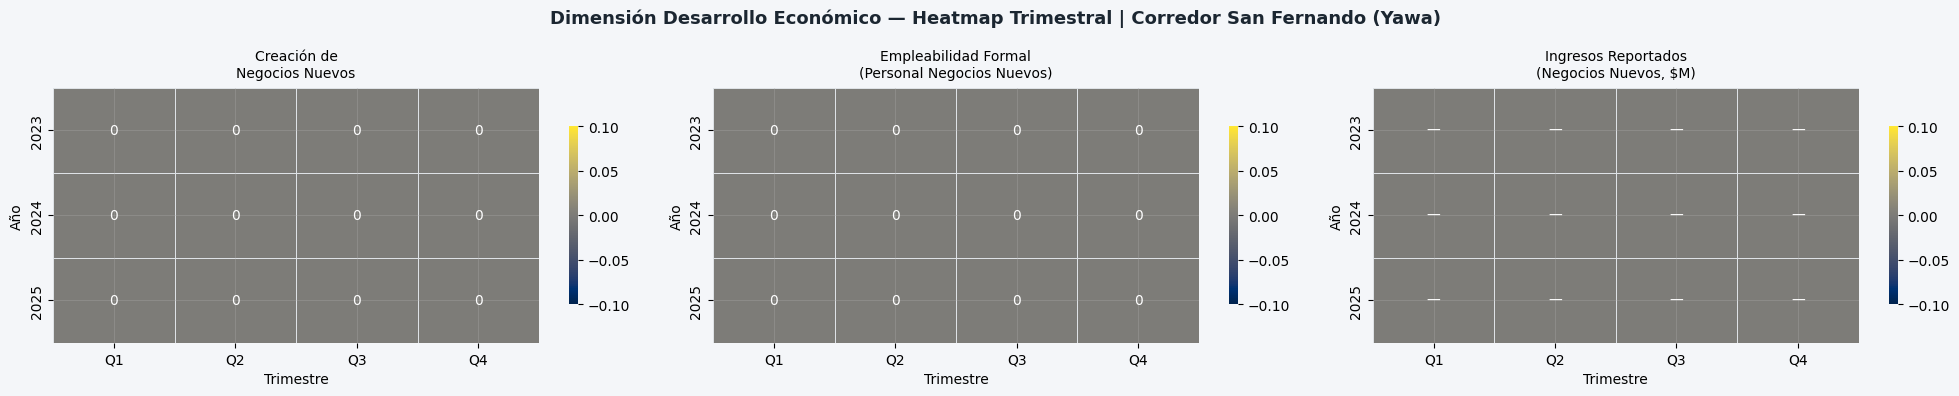

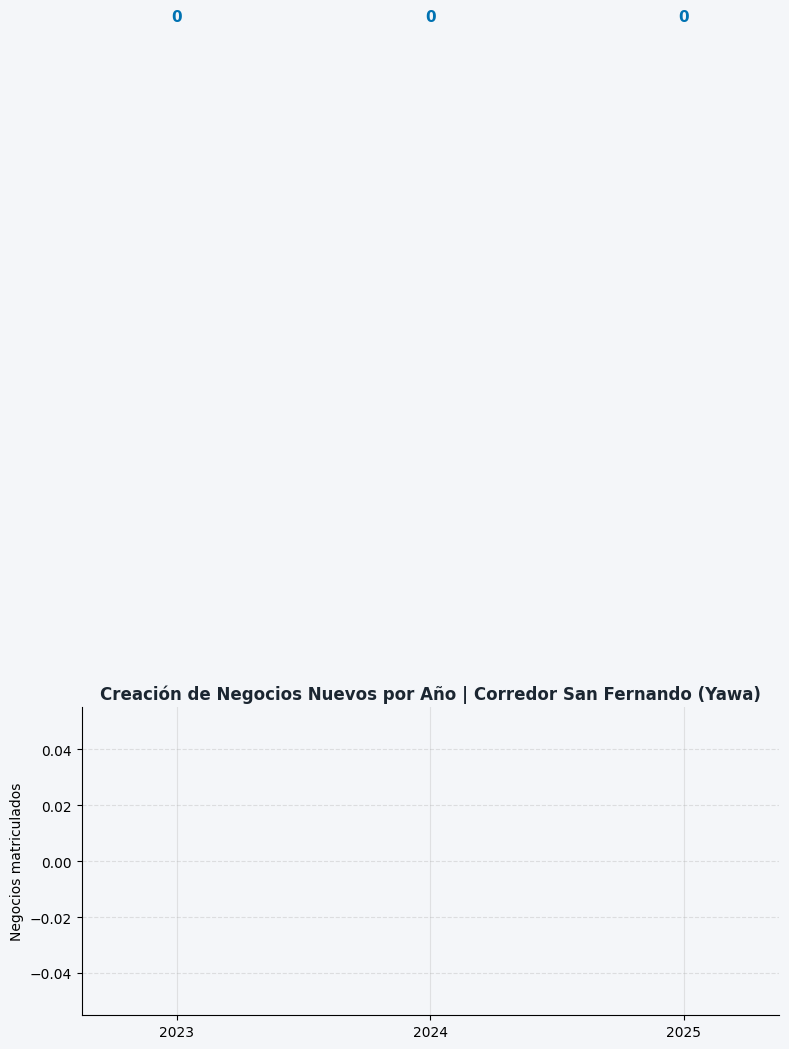

In [42]:
ANIOS_DE = [2023, 2024, 2025, 2026]
df_de["trim_mat"] = df_de["fecha_mat"].dt.quarter

rows_de_trim = []
for ano in ANIOS_DE:
    for trim in [1, 2, 3, 4]:
        sub = df_de[(df_de["anio_mat"] == ano) & (df_de["trim_mat"] == trim)]
        rows_de_trim.append({
            "periodo": f"{ano}-Q{trim}", "año": ano, "trimestre": trim,
            "negocios_nuevos": len(sub),
            "personal_nuevos": np.nan,   # empleo no disponible en la fuente (sin PERSONAL_O)
            "ingresos_nuevos": sub["ingresos_limpio"].sum(),
        })
df_de_trim = pd.DataFrame(rows_de_trim)

rows_de_anual = []
for ano in ANIOS_DE:
    sub = df_de[df_de["anio_mat"] == ano]
    rows_de_anual.append({
        "año": ano, "negocios_nuevos": len(sub),
        "personal_nuevos": np.nan,   # empleo no disponible en la fuente (sin PERSONAL_O)
        "ingresos_nuevos": sub["ingresos_limpio"].sum(),
    })
df_de_anual = pd.DataFrame(rows_de_anual)

print("Negocios nuevos matriculados por año (2023-2025):")
print(df_de_anual.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(20, 4), facecolor=BG)
fig.suptitle("Dimensión Desarrollo Económico — Heatmap Trimestral | Corredor San Fernando (Yawa)",
             fontsize=13, fontweight="bold", color="#1B2631")

for ax, col, titulo, fmt_fn in [
    (axes[0], "negocios_nuevos", "Creación de\nNegocios Nuevos", lambda x: f"{int(x)}"),
    (axes[1], "personal_nuevos", "Empleabilidad Formal\n(sin dato en esta fuente)", lambda x: "—"),
    (axes[2], "ingresos_nuevos", "Ingresos Reportados\n(Negocios Nuevos, $M)",
     lambda x: f"${x/1e6:.0f}M" if x >= 1e6 else ("—" if x == 0 else f"${x:,.0f}")),
]:
    pivot = df_de_trim.pivot(index="año", columns="trimestre", values=col).fillna(0)
    pivot.columns = ["Q1", "Q2", "Q3", "Q4"]
    # Nota: se evita .applymap/.map a proposito — .applymap se elimino en pandas 3.0
    # y conviene que esto corra igual en Colab con pandas 2.x o 3.x.
    annot = pivot.copy().astype(object)
    for r in pivot.index:
        for c in pivot.columns:
            annot.loc[r, c] = fmt_fn(pivot.loc[r, c])
    sns.heatmap(pivot, annot=annot, fmt="", cmap="cividis",
                linewidths=0.5, linecolor="#DEE2E6", ax=ax,
                annot_kws={"size": 10}, cbar_kws={"shrink": 0.7})
    ax.set_title(titulo, fontsize=10, pad=8)
    ax.set_xlabel("Trimestre")
    ax.set_ylabel("Año")

plt.tight_layout()
plt.savefig("corredor_san_fernando_de_heatmap_trim.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

fig2, ax2 = plt.subplots(figsize=(9, 4), facecolor=BG)
ax2.set_facecolor(BG)
x_pos = range(len(ANIOS_DE))
bars = ax2.bar(x_pos, df_de_anual["negocios_nuevos"], color=OKI_AZUL, alpha=0.85, width=0.5, zorder=3)
for bar, v in zip(bars, df_de_anual["negocios_nuevos"]):
    ax2.text(bar.get_x()+bar.get_width()/2, v+0.3, str(int(v)),
              ha="center", fontsize=11, fontweight="bold", color=OKI_AZUL)
ax2.set_xticks(list(x_pos))
ax2.set_xticklabels([str(a) for a in ANIOS_DE])
ax2.set_title("Creación de Negocios Nuevos por Año | Corredor San Fernando (Yawa)",
               fontsize=12, fontweight="bold", color="#1B2631")
ax2.set_ylabel("Negocios matriculados")
ax2.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig("corredor_san_fernando_de_evolucion_anual.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 15 — ITT Global y composición por dimensión

In [43]:
print(f"ITT {ZONA_NOMBRE} — 5 dimensiones (Seguridad 27% / Movilidad 22% / DesSocial 19% / EntornoU 17% / DesEco 15%)")
print(f"  EntornoU : NDVI + censo arbóreo propios de la zona (fuente: {FUENTE_ENTORNO_U})")
print("  DesSocial: VIF + Rinas + SPA (Educacion fuera de alcance de este repo — gestionada en otro repositorio)")
print(f"  2026     : {ANIOS_PARCIALES} tiene cobertura hasta Q3 (seguridad/cohesión) / Q2 (movilidad).")
print("             Se calcula y se muestra como GUÍA a la fecha (sin rótulo de parcial en los visuales).")
print()
cols = ["año","score_seguridad","score_movilidad","score_des_social",
        "score_entorno_u","score_des_eco","ITT","nivel"]
print(base[cols].round(1).to_string(index=False))
print()
print("Detalle contribucion al ITT:")
dim_map = [("Seg","seguridad","Seguridad"),("Mov","movilidad","Movilidad"),
           ("DS","des_social","DesSocial"),("EU","entorno_u","EntornoU"),
           ("DE","des_eco","DesEco")]
for _, row in base.iterrows():
    det = " + ".join(f"{d}={row[f'score_{k}']*PESOS[p]:.1f}" for d, k, p in dim_map)
    print(f"  {int(row['año'])}: {det} = ITT {row['ITT']:.1f} ({row['nivel']})")


ITT Corredor San Fernando (Yawa) — 5 dimensiones (Seguridad 27% / Movilidad 22% / DesSocial 19% / EntornoU 17% / DesEco 15%)
  EntornoU : NDVI + censo arbóreo propios de la zona (fuente: NDVI anual + censo arbóreo (datos propios de la zona))
  DesSocial: VIF + Rinas + SPA (Educacion fuera de alcance de este repo — gestionada en otro repositorio)
  2026     : [2026] tiene cobertura incompleta en TODAS las fuentes — su ITT se calcula
             y se muestra, pero su nivel queda marcado 'Parcial (no comparable)' en vez de un nivel
             real; no leer el salto 2025->2026 como mejora de transformacion (ver Celda 3).

 año  score_seguridad  score_movilidad  score_des_social  score_entorno_u  score_des_eco  ITT                   nivel
2023             35.5             36.0              55.2              0.0            0.0 28.0              Activacion
2024             48.7             50.3              72.0              0.0            0.0 37.9              Activacion
2025             

## Celda 16 — Heatmaps por dimensión (resumen anual)

Vista rápida anual de un vistazo. El detalle trimestral por indicador (con huecos NaN donde la fuente
aún no tiene corte) va en las celdas siguientes — mismo patrón que `04_itt_barrio_obrero_5dim.ipynb`.

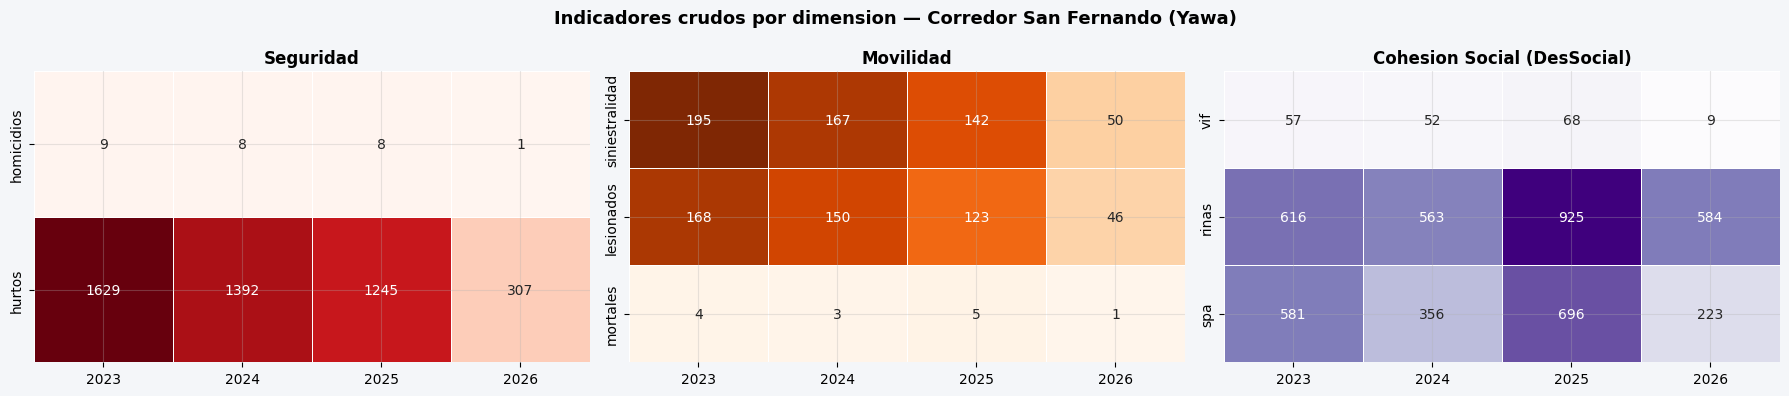

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), facecolor=BG)

heat_specs = [
    (axes[0], ["homicidios","hurtos"], "Seguridad", "Reds"),
    (axes[1], ["siniestralidad","lesionados","mortales"], "Movilidad", "Oranges"),
    (axes[2], ["vif","rinas","spa"], "Cohesion Social (DesSocial)", "Purples"),
]
for ax, cols_h, titulo, cmap in heat_specs:
    data = base.set_index("año")[cols_h].T
    sns.heatmap(data, annot=True, fmt=".0f", cmap=cmap, ax=ax, cbar=False,
                linewidths=0.5, linecolor="white")
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle(f"Indicadores crudos por dimension — {ZONA_NOMBRE}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("corredor_san_fernando_heatmap_indicadores.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 16B — Heatmaps trimestrales por indicador (Seguridad, Movilidad, DesSocial)

Año × trimestre, un panel por indicador, usando `corr_trim` (ya construido en la Celda 6, con `NaN`
donde la fuente aún no tiene cobertura — ver nota de 2026 parcial). Mismo patrón que las Celdas 9/10/11
de `04_itt_barrio_obrero_5dim.ipynb`: conteos crudos, no scores normalizados (la normalización solo aplica
al nivel anual para el cálculo del ITT, igual que en Obrero).

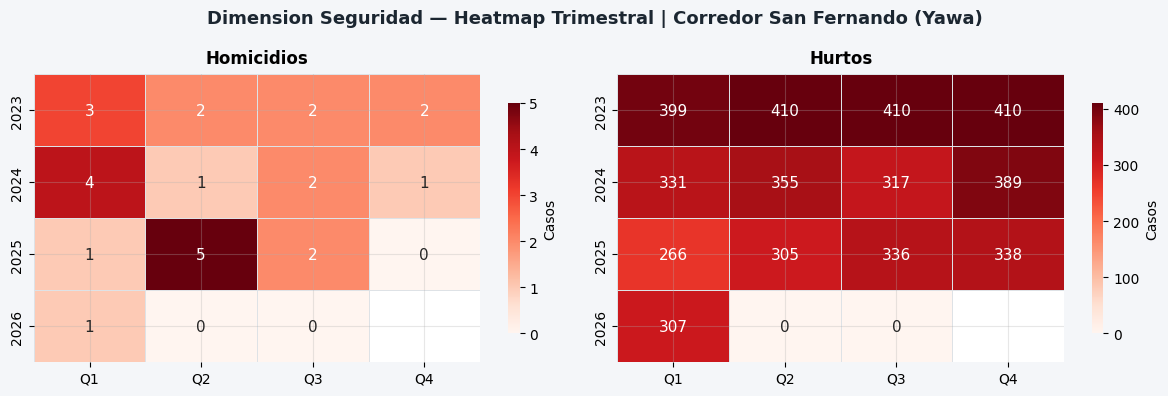

In [45]:
def heatmap_trimestral(cols_h, titulo_dim, cmap):
    n = len(cols_h)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 4), facecolor=BG)
    if n == 1:
        axes = [axes]
    fig.suptitle(f"Dimension {titulo_dim} — Heatmap Trimestral | {ZONA_NOMBRE}",
                 fontsize=13, fontweight="bold", color="#1B2631")
    for ax, (col, etiqueta) in zip(axes, cols_h):
        pivot = corr_trim.pivot(index="año", columns="trimestre", values=col)
        pivot.columns = ["Q1", "Q2", "Q3", "Q4"]
        mask_nan = pivot.isna()
        sns.heatmap(pivot, annot=True, fmt=".0f", cmap=cmap, mask=mask_nan,
                    linewidths=0.5, linecolor="#DEE2E6", ax=ax,
                    annot_kws={"size": 11}, cbar_kws={"label": "Casos", "shrink": 0.8})
        ax.set_title(etiqueta, fontweight="bold", pad=8)
        ax.set_xlabel("")
        ax.set_ylabel("")
    plt.tight_layout()
    return fig

fig_seg = heatmap_trimestral([("homicidios","Homicidios"), ("hurtos","Hurtos")], "Seguridad", "Reds")
fig_seg.savefig("corredor_san_fernando_heatmap_trim_seguridad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


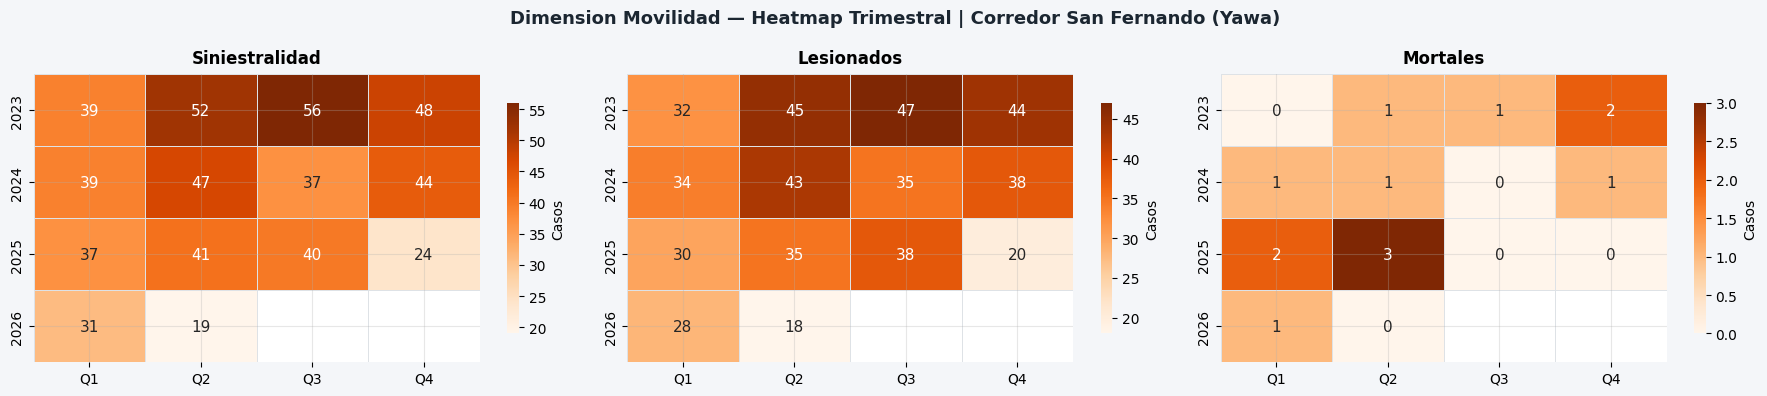

In [46]:
fig_mov = heatmap_trimestral(
    [("siniestralidad","Siniestralidad"), ("lesionados","Lesionados"), ("mortales","Mortales")],
    "Movilidad", "Oranges")
fig_mov.savefig("corredor_san_fernando_heatmap_trim_movilidad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


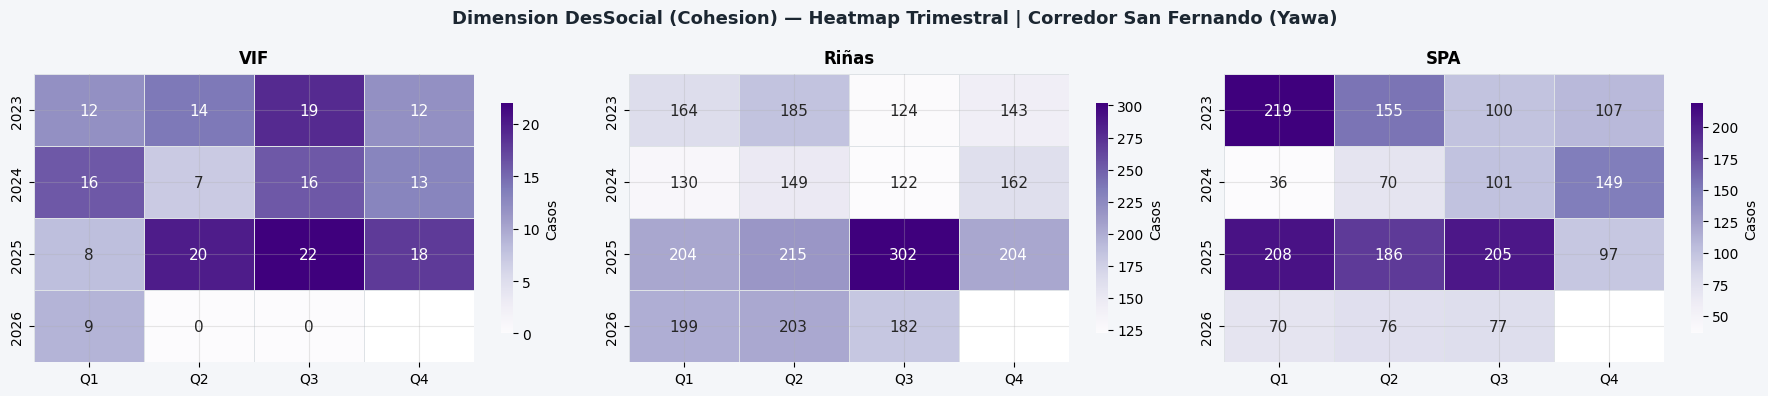

In [47]:
fig_ds = heatmap_trimestral(
    [("vif","VIF"), ("rinas","Riñas"), ("spa","SPA")],
    "DesSocial (Cohesion)", "Purples")
fig_ds.savefig("corredor_san_fernando_heatmap_trim_dessocial.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 16C — Evolución trimestral por indicador (línea + área)

Función reutilizable idéntica a la Celda 12/13/14 de Obrero: relleno bajo la línea, hueco visible donde
el valor es `NaN` (sin dato), y una línea vertical punteada marcando el último período con dato real —
para que no se confunda "sin dato todavía" con "cero".

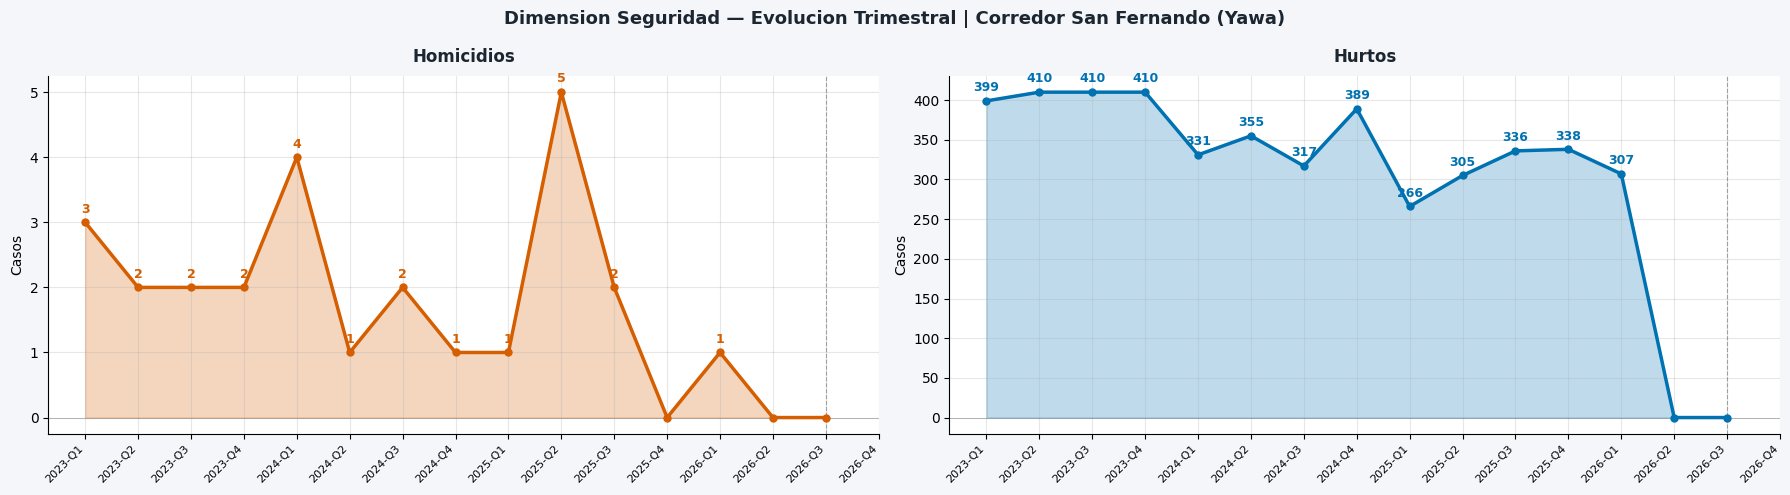

In [48]:
periodos = corr_trim["periodo"].values
x = list(range(len(periodos)))

def plot_linefill(ax, col, titulo, color):
    vals = corr_trim[col].values.astype(float)
    valid = ~pd.isna(vals)
    ax.fill_between(x, np.where(valid, vals, np.nan), alpha=0.25, color=color)
    ax.plot(x, np.where(valid, vals, np.nan), color=color,
            linewidth=2.5, marker="o", markersize=5, zorder=3)
    for i, v in enumerate(vals):
        if pd.notna(v) and v > 0:
            ax.annotate(str(int(v)), (i, v), textcoords="offset points", xytext=(0, 7),
                        ha="center", fontsize=9, fontweight="bold", color=color)
    ultimo_valido = max(i for i, v in enumerate(vals) if pd.notna(v))
    ax.axvline(ultimo_valido, color=OKI_GRIS, linewidth=0.8, linestyle="--", alpha=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(periodos, rotation=45, ha="right", fontsize=8)
    ax.set_title(titulo, fontweight="bold", pad=10, color="#1B2631")
    ax.set_ylabel("Casos")
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), facecolor=BG)
fig.suptitle(f"Dimension Seguridad — Evolucion Trimestral | {ZONA_NOMBRE}",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "homicidios", "Homicidios", OKI_BERMELL)
plot_linefill(axes[1], "hurtos", "Hurtos", OKI_AZUL)
plt.tight_layout()
plt.savefig("corredor_san_fernando_evol_trim_seguridad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


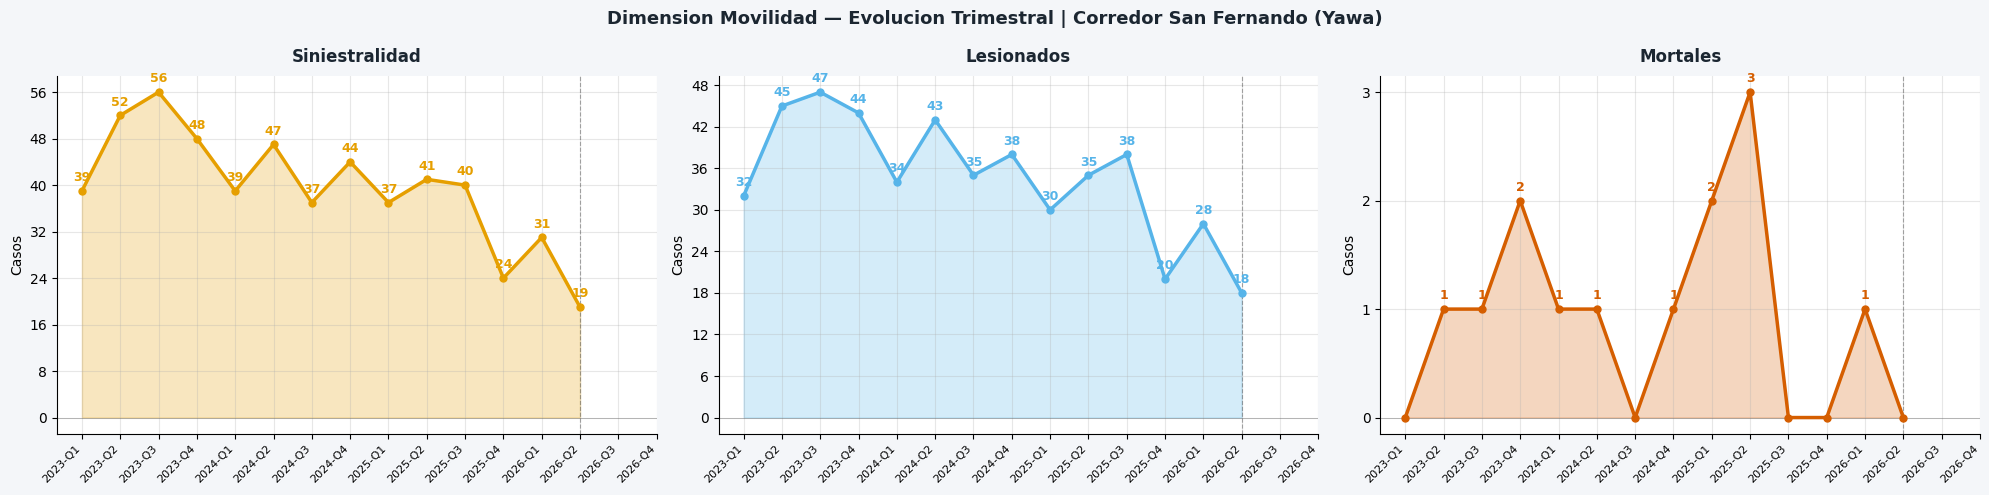

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle(f"Dimension Movilidad — Evolucion Trimestral | {ZONA_NOMBRE}",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "siniestralidad", "Siniestralidad", OKI_NARANJA)
plot_linefill(axes[1], "lesionados", "Lesionados", OKI_AZUL_C)
plot_linefill(axes[2], "mortales", "Mortales", OKI_BERMELL)
plt.tight_layout()
plt.savefig("corredor_san_fernando_evol_trim_movilidad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


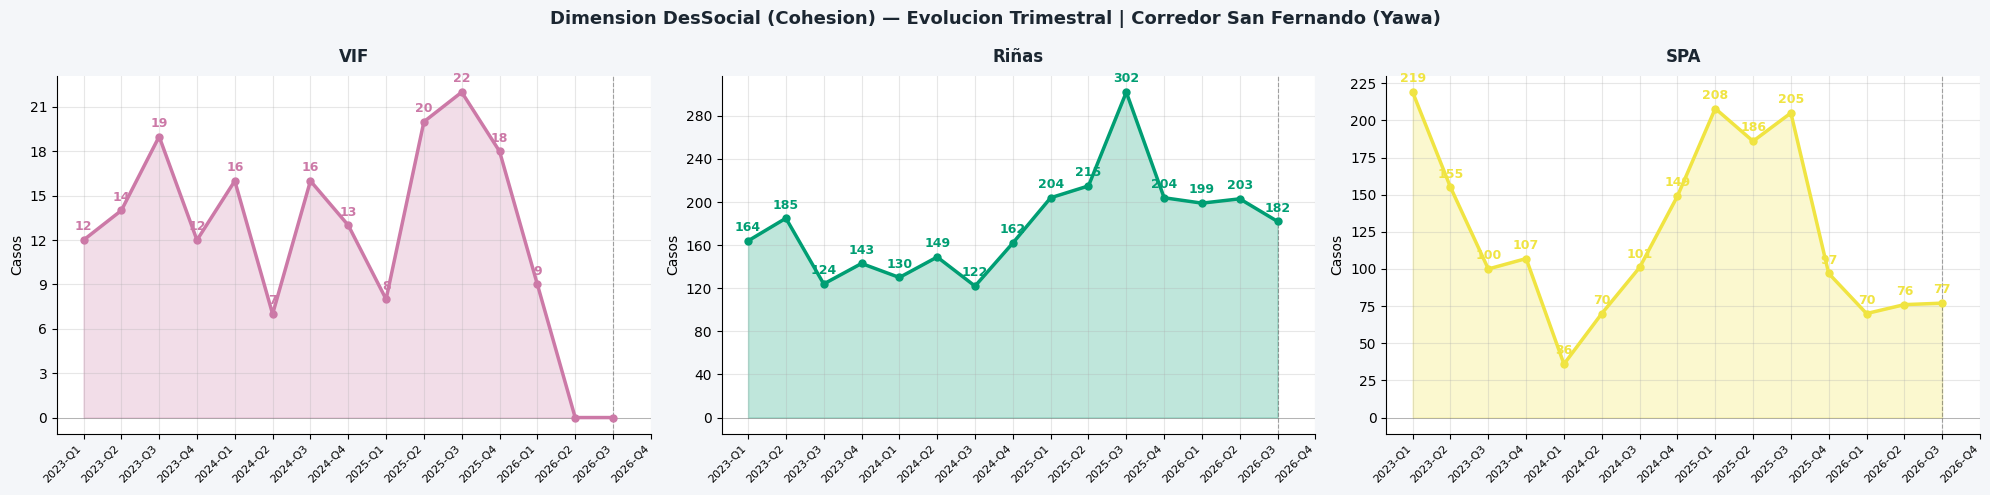

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle(f"Dimension DesSocial (Cohesion) — Evolucion Trimestral | {ZONA_NOMBRE}",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "vif", "VIF", OKI_MORADO)
plot_linefill(axes[1], "rinas", "Riñas", OKI_VERDE)
plot_linefill(axes[2], "spa", "SPA", OKI_AMARILLO)
plt.tight_layout()
plt.savefig("corredor_san_fernando_evol_trim_dessocial.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda EU-Card — Entorno Urbano: NDVI anual + censo arbóreo (dashboard)

Dashboard de la dimensión con los datos reales de la zona: evolución del NDVI medio 2023-2026 y el conteo
de árboles vivos del censo. Reemplaza la antigua tarjeta de déficit habitacional (proxy ya retirado).

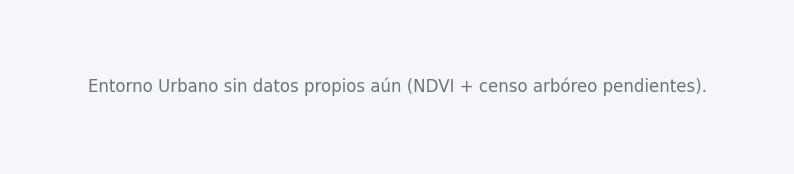

In [51]:
anios_ndvi = df_entorno["año"].tolist()
vals_ndvi  = df_entorno["ndvi"].tolist()
_hay_ndvi  = any(pd.notna(v) for v in vals_ndvi)

def _dashboard_entorno():
    fig = plt.figure(figsize=(15, 4.2), facecolor=BG)
    fig.suptitle(f"Entorno Urbano · NDVI anual + censo arbóreo — {ZONA_NOMBRE}",
                 fontsize=12, fontweight="bold", color="#1B2631", y=1.02)
    ax_ndvi = fig.add_axes([0.06, 0.16, 0.52, 0.74])
    _vals_plot = [v if pd.notna(v) else np.nan for v in vals_ndvi]
    ax_ndvi.plot(anios_ndvi, _vals_plot, marker="o", linewidth=2.4, color=OKI_VERDE, zorder=3)
    _finite = [v for v in vals_ndvi if pd.notna(v)]
    if _finite:
        ax_ndvi.fill_between(anios_ndvi, _vals_plot, min(_finite) * 0.9, alpha=0.12, color=OKI_VERDE)
    for x, y in zip(anios_ndvi, vals_ndvi):
        if pd.notna(y):
            ax_ndvi.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 8),
                             ha="center", fontsize=9, fontweight="bold", color=OKI_GRIS)
    ax_ndvi.set_title("NDVI medio anual (vegetación)", fontsize=10, color="#1B2631")
    ax_ndvi.set_xticks(anios_ndvi)
    ax_ndvi.set_ylabel("NDVI medio")
    ax_ndvi.grid(True, alpha=0.3)

    def card2(ax, top, valor, bot, color_val):
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
        ax.add_patch(mpatches.FancyBboxPatch((0.04, 0.04), 0.92, 0.92, boxstyle="round,pad=0.03",
                     linewidth=1.5, edgecolor="#DEE2E6", facecolor="white"))
        ax.text(0.5, 0.78, top, ha="center", fontsize=8, color="#6C757D", fontweight="bold", transform=ax.transAxes)
        ax.text(0.5, 0.46, valor, ha="center", fontsize=22, color=color_val, fontweight="bold", transform=ax.transAxes)
        ax.text(0.5, 0.15, bot, ha="center", fontsize=8, color="#888888", transform=ax.transAxes)

    score_eu_prom = base["score_entorno_u"].mean()
    _n0 = next((v for v in vals_ndvi if pd.notna(v)), float("nan"))
    _n1 = next((v for v in reversed(vals_ndvi) if pd.notna(v)), float("nan"))
    card2(fig.add_axes([0.62, 0.52, 0.17, 0.38]), "ÁRBOLES VIVOS",
          f"{ARBOLADO_VIVO}", "Censo dentro\ndel polígono", OKI_VERDE)
    card2(fig.add_axes([0.81, 0.52, 0.17, 0.38]), "NDVI 2023→2026",
          f"{_n0:.3f}→{_n1:.3f}", "Serie satelital\nanual", OKI_AZUL)
    card2(fig.add_axes([0.62, 0.08, 0.17, 0.38]), "SCORE EU PROM.",
          f"{score_eu_prom:.1f}/100", "mean(NDVI, arbolado)", OKI_NARANJA)
    card2(fig.add_axes([0.81, 0.08, 0.17, 0.38]), "PESO EN ITT",
          "17 %", "Entorno Urbano\ncon dato propio", OKI_AZUL)
    fig.text(0.5, -0.04,
        "Fuente: censo arbóreo municipal + NDVI satelital anual recortado al polígono de la zona. "
        "Método idéntico a Av. Ciudad de Cali: score_entorno_u = media(score_NDVI, score_arbolado).",
        ha="center", fontsize=8, color="#888888", style="italic")
    plt.savefig("corredor_san_fernando_eu_ndvi_arbolado_card.png", dpi=150, bbox_inches="tight", facecolor=BG)
    plt.show()

if _hay_ndvi or ARBOLADO_VIVO > 0:
    _dashboard_entorno()
else:
    # Entorno Urbano sin datos propios aún (NDVI + censo arbóreo pendientes).
    fig, ax = plt.subplots(figsize=(10, 2), facecolor=BG)
    ax.axis("off")
    ax.text(0.5, 0.5, "Entorno Urbano sin datos propios aún (NDVI + censo arbóreo pendientes).",
            ha="center", va="center", fontsize=12, color="#6C757D")
    plt.show()


## Celda 17 — Radar ITT: 5 dimensiones

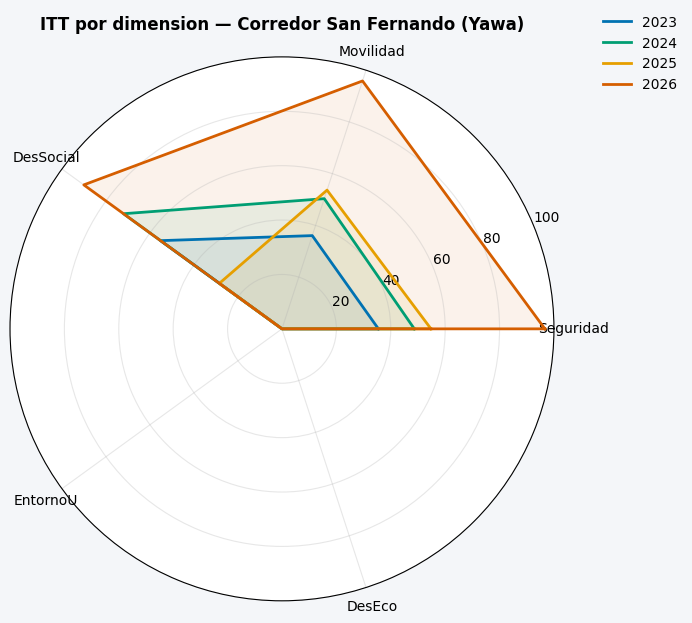

In [52]:
dims_radar  = ["score_seguridad","score_movilidad","score_des_social","score_entorno_u","score_des_eco"]
lbls_radar  = ["Seguridad","Movilidad","DesSocial","EntornoU","DesEco"]
angles = np.linspace(0, 2*np.pi, len(dims_radar), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True), facecolor=BG)
colores_anio = [OKI_AZUL, OKI_VERDE, OKI_NARANJA, OKI_BERMELL]
for i, (_, row) in enumerate(base.iterrows()):
    vals = [row[d] if pd.notna(row[d]) else 0 for d in dims_radar]
    vals += vals[:1]
    ax.plot(angles, vals, linewidth=2, label=str(int(row["año"])), color=colores_anio[i % 4])
    ax.fill(angles, vals, alpha=0.08, color=colores_anio[i % 4])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(lbls_radar)
ax.set_ylim(0, 100)
ax.set_title(f"ITT por dimension — {ZONA_NOMBRE}", fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), frameon=False)
plt.tight_layout()
plt.savefig("corredor_san_fernando_radar_itt.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 18 — Evolución del ITT y composición por dimensión

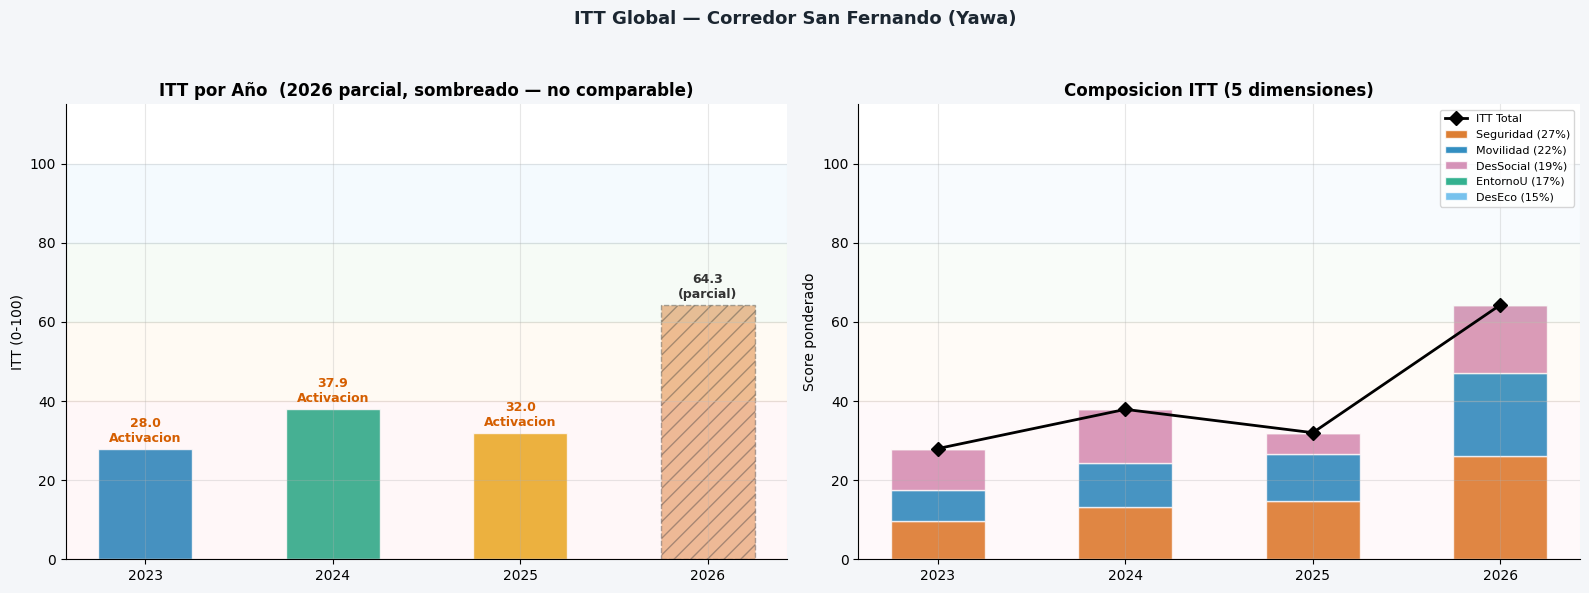

In [53]:
band_configs = [(0,40,"#FFCDD2","Activacion"),(40,60,"#FFE0B2","Consolidacion"),
                (60,80,"#C8E6C9","Transformacion"),(80,100,"#BBDEFB","Escala")]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)
fig.suptitle(f"ITT Global — {ZONA_NOMBRE}", fontsize=13, fontweight="bold", color="#1B2631")

ax1 = axes[0]
bars = ax1.bar(base["año"], base["ITT"], color=[OKI_AZUL, OKI_VERDE, OKI_NARANJA, OKI_BERMELL],
                alpha=0.85, edgecolor="white", width=0.5)
for bar, val, nivel, año in zip(bars, base["ITT"], base["nivel"], base["año"]):
    etiqueta = f"{val:.1f}\n{nivel}"
    ax1.text(bar.get_x()+bar.get_width()/2, val+1, etiqueta,
              ha="center", va="bottom", fontsize=9, fontweight="bold",
              color=NIVEL_COLORS.get(nivel, OKI_GRIS))
for y0, y1, c, _ in band_configs:
    ax1.axhspan(y0, y1, alpha=0.15, color=c)
ax1.set_title("ITT por Año", fontweight="bold")
ax1.set_ylim(0, 115)
ax1.set_ylabel("ITT (0-100)")
ax1.set_xticks(base["año"])

ax2 = axes[1]
dims  = ["score_seguridad","score_movilidad","score_des_social","score_entorno_u","score_des_eco"]
lbls  = ["Seguridad","Movilidad","DesSocial","EntornoU","DesEco"]
pesos = [PESOS["Seguridad"], PESOS["Movilidad"], PESOS["DesSocial"], PESOS["EntornoU"], PESOS["DesEco"]]
cols_c = [OKI_BERMELL, OKI_AZUL, OKI_MORADO, OKI_VERDE, OKI_AZUL_C]

bottom = np.zeros(len(base))
for dim, lbl, peso, col in zip(dims, lbls, pesos, cols_c):
    vals = base[dim].fillna(0).values * peso
    ax2.bar(base["año"], vals, bottom=bottom, label=f"{lbl} ({peso:.0%})",
            color=col, alpha=0.8, edgecolor="white", width=0.5)
    bottom += vals
ax2.plot(base["año"], base["ITT"], "D-", color="black", linewidth=2, markersize=7, label="ITT Total", zorder=5)
for y0, y1, c, _ in band_configs:
    ax2.axhspan(y0, y1, alpha=0.1, color=c)
ax2.set_title("Composicion ITT (5 dimensiones)", fontweight="bold")
ax2.set_ylim(0, 115)
ax2.set_ylabel("Score ponderado")
ax2.set_xticks(base["año"])
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("corredor_san_fernando_itt_global.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 19 — Exportar a Excel

In [54]:
import openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter
OUT_DIR = REPO / "outputs" / "itt_corredor_san_fernando"
OUT_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_PATH = OUT_DIR / "ITT_Corredor_San_Fernando_Consolidado.xlsx"

cols_anual = ["año","score_seguridad","score_movilidad","score_des_social",
              "score_entorno_u","score_des_eco","ITT","nivel"]
df_itt_anual = base[cols_anual].copy().round(2)
# 2026 se muestra como GUÍA (cobertura seguridad/cohesión hasta Q3, movilidad hasta Q2); sin rótulo "parcial".
df_itt_anual["cobertura"] = df_itt_anual["año"].apply(
    lambda a: "2026: datos a la fecha (seguridad/cohesión hasta Q3, movilidad hasta Q2) — guía"
    if a in ANIOS_PARCIALES else "Año completo")

df_seg = base[["año","homicidios","hurtos","score_homicidios","score_hurtos","score_seguridad"]].round(2)
df_mov = base[["año","siniestralidad","lesionados","mortales",
               "score_siniestralidad","score_lesionados","score_mortales","score_movilidad"]].round(2)

# Cohesión + Educación (ambos componen DesSocial en esta zona, como en Ciudad Paraíso)
df_coh = base[["año","vif","rinas","spa","score_vif","score_rinas","score_spa",
               "score_matricula","score_desercion","score_des_social"]].round(2)
df_coh = df_coh.rename(columns={"score_des_social": "score_DesSocial_total"})

# Entorno Urbano: NDVI + arbolado + habitabilidad (vivienda)
df_eu = base[["año","ndvi","arbolado","score_ndvi","score_arbolado",
              "score_habitabilidad","score_entorno_u"]].round(4).copy()
df_eu["fuente"] = FUENTE_ENTORNO_U
df_eu["nota"] = ("NDVI medio anual (satelital) + censo arbóreo + habitabilidad (1 - déficit habitacional 2024). "
                 "score_entorno_u = mean(score_ndvi, score_arbolado, score_habitabilidad). "
                 "Vivienda es corte único estructural 2024 (constante en la serie).")

df_de_export = df_de_scores.copy().round(2)

# Educación (IE Liceo Departamental) — detalle de matrícula/deserción/repitencia
df_educ_export = df_educ[["año","matricula","desertores","repitentes",
                          "tasa_desercion","tasa_repitencia",
                          "score_matricula","score_desercion","score_educ_des"]].round(2)

# Vivienda (Secretaría de Vivienda) — déficit por barrio, spatial join + prorrateo
if "VIVIENDA_DETALLE" in dir() and VIVIENDA_DETALLE is not None:
    df_viv = VIVIENDA_DETALLE.copy()
    df_viv.columns = ["barrio","total_hogares","deficit_habitacional","deficit_cuant","deficit_cualit",
                      "pct_area_en_poligono","hogares_prorrateados","deficit_prorrateado"]
    df_viv = df_viv.round(3)
else:
    df_viv = pd.DataFrame({"nota": ["Vivienda no disponible en esta corrida."]})

df_viv_resumen = pd.DataFrame({
    "indicador": ["Barrios que intersectan el polígono","Hogares (prorrateados)","Déficit (prorrateado)",
                  "Tasa de déficit habitacional","Habitabilidad (score, 1-tasa)","Subsidios de mejoramiento en la zona"],
    "valor": [len(df_viv) if "barrio" in df_viv.columns else 0,
              round(float(df_viv["hogares_prorrateados"].sum()),0) if "hogares_prorrateados" in df_viv.columns else None,
              round(float(df_viv["deficit_prorrateado"].sum()),0) if "deficit_prorrateado" in df_viv.columns else None,
              f"{(1 - base['score_habitabilidad'].iloc[0]/100)*100:.1f}%" if not pd.isna(base['score_habitabilidad'].iloc[0]) else "",
              base['score_habitabilidad'].iloc[0],
              "0 (comuna 19 no aparece en la base de subsidios 2024-jun2026)"],
})

df_trim_export = corr_trim.copy()
df_auditoria = pd.DataFrame({
    "fuente": ["Homicidios","Hurtos","Comparendos","VIF","Siniestros","Desarrollo Económico","Vivienda (SISBÉN)","Educación (Liceo Dptal)"],
    "metodo_espacial": ["sjoin within al polígono"]*5 + ["sjoin within (Cámara geocodificada)",
                        "sjoin + prorrateo por área (shapefile SISBÉN)","sjoin de sedes al polígono (DANE 176001001745)"],
})

sheets = {
    "ITT_Resumen":               df_itt_anual,
    "Seguridad":                 df_seg,
    "Movilidad":                 df_mov,
    "Cohesion_y_Educacion":      df_coh,
    "Educacion_LiceoDptal":      df_educ_export,
    "Entorno_Urbano":            df_eu,
    "Vivienda_SecVivienda":      df_viv,
    "Vivienda_Resumen":          df_viv_resumen,
    "Desarrollo_Economico":      df_de_export,
    "Indicadores_Trimestrales":  df_trim_export,
    "Auditoria_Spatial_Join":    df_auditoria,
}
with pd.ExcelWriter(str(EXPORT_PATH), engine="openpyxl") as writer:
    for sheet_name, df in sheets.items():
        df.to_excel(writer, sheet_name=sheet_name, index=False)
    wb = writer.book
    header_fill = PatternFill("solid", fgColor="1B4F8A")
    header_font = Font(color="FFFFFF", bold=True)
    thin   = Side(style="thin", color="CCCCCC")
    border = Border(left=thin, right=thin, top=thin, bottom=thin)
    for ws in wb.worksheets:
        for cell in ws[1]:
            cell.fill = header_fill
            cell.font = header_font
            cell.alignment = Alignment(horizontal="center", wrap_text=True)
        for col in ws.columns:
            max_len = max((len(str(c.value)) for c in col if c.value), default=8)
            ws.column_dimensions[get_column_letter(col[0].column)].width = min(max_len + 2, 40)
print(f"Exportado: {EXPORT_PATH}  ({len(sheets)} hojas)")


Exportado: /content/itt_repos_cali/outputs/itt_corredor_san_fernando/ITT_Corredor_San_Fernando_Consolidado.xlsx


## Celda final — Comparación por subzonas vs. Corredor completo

Sub-filtra la **misma data** (seguridad, cohesión, movilidad, desarrollo económico, vivienda) a cada subzona interna (zona_01/02/03) por *spatial join* a su subpolígono, y la compara contra el Corredor San Fernando completo en una tabla sencilla. Permite ver qué parte del corredor concentra cada fenómeno. Conteos acumulados 2023-2026 a la fecha (incluye 2026 como guía).

In [ ]:
# ── Comparación por subzonas vs. Corredor completo ────────────────────────────
# Sub-filtra la MISMA data cruda a cada subpolígono (spatial join 'within') y resume
# por dimensión. Tabla sencilla: una fila por zona (Corredor + 3 subzonas + Yawa).
from shapely.geometry import shape as _shape

# Polígonos de comparación: corredor completo + subzonas + yawa
_zonas_cmp = {"Corredor San Fernando": gdf_zona_wgs.geometry.union_all()}
for _nz, _pz in SUBZONAS.items():
    if os.path.exists(_pz):
        _zonas_cmp[_nz] = gpd.read_file(_pz).to_crs("EPSG:4326").geometry.union_all()
if os.path.exists(PATH_YAWA):
    _zonas_cmp["Yawa"] = gpd.read_file(PATH_YAWA).to_crs("EPSG:4326").geometry.union_all()

def _puntos_gdf(raw):
    """GeoDataFrame de puntos (EPSG:4326) a partir de un FeatureCollection raw."""
    feats = [f for f in raw["features"] if (f.get("geometry") or {}).get("type") == "Point"]
    if not feats:
        return gpd.GeoDataFrame({"geometry": []}, crs="EPSG:4326")
    geom = [_shape(f["geometry"]) for f in feats]
    props = [f["properties"] for f in feats]
    return gpd.GeoDataFrame(props, geometry=geom, crs="EPSG:4326")

# GeoDataFrames de eventos (toda la serie, puntos)
_g_hom  = _puntos_gdf(raw_hom)
_g_hur  = _puntos_gdf(raw_hur)
_g_comp = _puntos_gdf(raw_comp)
_g_vif  = _puntos_gdf(raw_vif)
_g_sin  = _puntos_gdf(raw_sin)

# Desarrollo Económico: negocios del consolidado (lat/lon) como puntos
_g_de = gpd.GeoDataFrame(
    df_de.copy(),
    geometry=gpd.points_from_xy(pd.to_numeric(df_de["longitud"], errors="coerce"),
                                pd.to_numeric(df_de["latitud"], errors="coerce")),
    crs="EPSG:4326",
)

def _n_dentro(gdf, poly):
    if gdf is None or len(gdf) == 0:
        return 0
    return int(gdf.geometry.within(poly).sum())

def _rinas(gdf, poly):
    if "agrupado" not in gdf.columns or len(gdf) == 0:
        return 0
    sub = gdf[gdf["agrupado"].astype(str).str.startswith("RI")]
    return _n_dentro(sub, poly)

def _spa(gdf, poly):
    if "agrupado" not in gdf.columns or len(gdf) == 0:
        return 0
    sub = gdf[gdf["agrupado"] == "SUSTANCIAS PSICOACTIVAS"]
    return _n_dentro(sub, poly)

rows_cmp = []
for _nz, _poly in _zonas_cmp.items():
    area_ha = round(gpd.GeoSeries([_poly], crs="EPSG:4326").to_crs("EPSG:3115").area.iloc[0] / 10000, 1)
    rows_cmp.append(dict(
        zona=_nz,
        area_ha=area_ha,
        homicidios=_n_dentro(_g_hom, _poly),
        hurtos=_n_dentro(_g_hur, _poly),
        rinas=_rinas(_g_comp, _poly),
        spa=_spa(_g_comp, _poly),
        vif=_n_dentro(_g_vif, _poly),
        siniestros=_n_dentro(_g_sin, _poly),
        negocios_activos=_n_dentro(_g_de, _poly),
    ))
df_subzonas = pd.DataFrame(rows_cmp)

# Densidad de hurtos por hectárea (indicador comparable entre zonas de distinto tamaño)
df_subzonas["hurtos_x_ha"] = (df_subzonas["hurtos"] / df_subzonas["area_ha"]).round(2)
df_subzonas["negocios_x_ha"] = (df_subzonas["negocios_activos"] / df_subzonas["area_ha"]).round(2)

print("Comparación por subzonas vs. Corredor San Fernando (conteos acumulados 2023-2026, a la fecha):")
print(df_subzonas.to_string(index=False))
print()
print("Nota: 'negocios_activos' = total del consolidado dentro de cada polígono (stock, no por año).")
print("Las subzonas 1/2/3 son particiones internas del corredor; su suma no es exactamente el total")
print("del corredor por solapes de borde y puntos sobre límites.")
df_subzonas
